# Mô hình Perceptron: minh họa trực quan bằng Python

Tài liệu này đi theo năm mục của bài giảng **Perceptron**, mỗi khái niệm đều có một hình vẽ hoặc một phép tính chạy được:

| Mục | Nội dung | Bạn sẽ thấy |
|---|---|---|
| 1 | Từ hồi quy tuyến tính đến phân loại | Vì sao "hồi quy rồi đặt ngưỡng" dễ hỏng |
| 2 | Mô hình Perceptron | Điểm số, đường biên, margin, ý nghĩa của w₀ và w̃ |
| 3 | Huấn luyện | Hàm mất mát, quy tắc cập nhật, chạy từng bước |
| 4 | Cơ chế học | Thứ tự mẫu, định lý hội tụ, bài toán XOR |
| 5 | Cài đặt và đánh giá | Tập kiểm tra, ma trận nhầm lẫn, precision/recall, scikit-learn |

**Cách dùng.** Chạy lần lượt từng ô (Shift+Enter). Các ô có tiêu đề **"Giải thích mã"** giảng kỹ những dòng khó đọc.

**Quy ước ký hiệu (giữ nguyên như bài giảng).**
- Nhãn $y_i \in \{-1,+1\}$: **+1 là đậu** (ô vuông xanh), **−1 là rớt** (chấm tròn cam).
- $\mathbf{x}_i$ là vector **hàng** có phần tử đầu bằng 1, $\mathbf{w}$ là vector **cột**.
- Điểm số $s=\mathbf{x}\mathbf{w}$, dự đoán $\hat y=\mathrm{sign}(s)$ với $\mathrm{sign}(0)=+1$, margin $m=y\cdot s$.

In [1]:
# ===== Ô 0: nạp thư viện và các hàm vẽ dùng chung =====
import os
import sys
import itertools
import warnings
from collections import Counter

import numpy as np
import matplotlib

# Chạy bằng "python perceptron_minh_hoa.py" trên máy không có màn hình thì dùng backend "Agg"
# (chỉ lưu ảnh). Trong Jupyter ("ipykernel" có mặt) thì giữ nguyên để ảnh hiện ngay dưới ô.
if "ipykernel" not in sys.modules and not os.environ.get("DISPLAY") and sys.platform.startswith("linux"):
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message=".*non-interactive.*")

MAU_DAU = "#2563EB"   # xanh: đậu (+1)
MAU_ROT = "#F97316"   # cam : rớt (-1)
MAU_NHAN = "#0B8F7A"  # xanh ngọc: điểm nhấn
THU_MUC_HINH = "hinh_perceptron"
os.makedirs(THU_MUC_HINH, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10.5,
})


def hien(fig, ten):
    """Lưu hình vào thư mục hinh_perceptron/ rồi hiển thị."""
    fig.tight_layout()
    fig.savefig(os.path.join(THU_MUC_HINH, ten + ".png"), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# --- Các hàm của mô hình (dùng lại ở mọi mục) ---
def them_bias(X):
    """Thêm cột toàn số 1 vào đầu ma trận đặc trưng: (n, d) -> (n, d+1)."""
    return np.hstack([np.ones((X.shape[0], 1)), X])


def du_doan(Xb, w):
    """Nhãn dự đoán y_hat = sign(Xw), quy ước sign(0) = +1."""
    return np.where(Xb @ w >= 0, 1, -1)


def huan_luyen(Xb, y, eta=1.0, t_max=100, w0=None, thu_tu=None):
    """Thuật toán Perceptron (cập nhật ngay sau mỗi mẫu khi m = y * (x @ w) <= 0).

    thu_tu : None -> duyệt 0..n-1; hoặc một dãy chỉ số để duyệt theo thứ tự đó.
    Trả về: w cuối, lich_su (số cập nhật mỗi epoch), quy_dao (w sau mỗi lần cập nhật).
    """
    n, d1 = Xb.shape
    w = np.zeros(d1) if w0 is None else np.array(w0, dtype=float)
    thu_tu = range(n) if thu_tu is None else thu_tu
    lich_su, quy_dao = [], []
    for _ in range(t_max):
        so_cap_nhat = 0
        for i in thu_tu:
            if y[i] * (Xb[i] @ w) <= 0:          # mẫu sai (hoặc nằm đúng trên biên)
                w = w + eta * y[i] * Xb[i]       # quy tắc cập nhật
                quy_dao.append(w.copy())
                so_cap_nhat += 1
        lich_su.append(so_cap_nhat)
        if so_cap_nhat == 0:                     # một epoch không sai mẫu nào: dừng
            break
    return w, lich_su, quy_dao


def ve_du_lieu(ax, X, y, co=60, nhan_so=False, alpha=1.0):
    """Vẽ điểm dữ liệu: đậu = ô vuông xanh, rớt = chấm tròn cam."""
    # X[y == 1] lọc các hàng có nhãn +1; ".T" chuyển (n,2) thành (2,n); "*" tách thành hai đối số x và y.
    ax.scatter(*X[y == 1].T, c=MAU_DAU, marker="s", s=co, alpha=alpha, label="Đậu (+1)", zorder=3)
    ax.scatter(*X[y == -1].T, c=MAU_ROT, marker="o", s=co, alpha=alpha, label="Rớt (−1)", zorder=3)
    if nhan_so:
        for i, (a, b) in enumerate(X):
            ax.annotate(str(i + 1), (a, b), textcoords="offset points", xytext=(7, 6), fontsize=10, fontweight="bold")


def ve_duong_bien(ax, w, xlim, ylim, to_vung=True, mui_ten=False, **kw):
    """Vẽ đường biên w0 + w1*x1 + w2*x2 = 0 và (tuỳ chọn) tô hai vùng dự đoán."""
    # meshgrid biến hai dãy 1 chiều thành hai lưới 2 chiều để tính điểm số tại mọi điểm trên màn hình.
    u, v = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
    s = w[0] + w[1] * u + w[2] * v
    if to_vung:
        # contourf tô màu theo dấu của s: vùng s>=0 màu xanh nhạt, vùng s<0 màu cam nhạt.
        ax.contourf(u, v, np.where(s >= 0, 1, -1), levels=[-2, 0, 2], colors=[MAU_ROT, MAU_DAU], alpha=0.10)
    if np.hypot(w[1], w[2]) > 1e-12:
        ax.contour(u, v, s, levels=[0], colors=kw.get("mau", "k"), linewidths=kw.get("lw", 2),
                   linestyles=kw.get("ls", "solid"))   # đường mức s = 0 chính là đường biên
        if mui_ten:  # mũi tên pháp tuyến chỉ về phía s tăng
            n = np.array(w[1:]) / np.hypot(w[1], w[2])
            tam = np.array([(xlim[0] + xlim[1]) / 2, (ylim[0] + ylim[1]) / 2])
            f = (w[0] + w[1:] @ tam) / np.hypot(w[1], w[2])
            goc = tam - f * n                                   # hình chiếu của tâm lên đường biên
            ax.annotate("", xy=goc + 1.2 * n, xytext=goc, arrowprops=dict(arrowstyle="-|>", color=MAU_DAU, lw=2.5))
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel("$x_1$: số giờ tự học")
    ax.set_ylabel("$x_2$: số buổi vắng")


# --- Dữ liệu 6 sinh viên dùng xuyên suốt bài ---
X_sv = np.array([[2, 4], [3, 3], [4, 5], [6, 1], [8, 2], [9, 0]], dtype=float)
y_sv = np.array([-1, -1, -1, 1, 1, 1])
Xb_sv = them_bias(X_sv)
print("Ma trận đặc trưng X (cột đầu là bias 1):")
print(Xb_sv)
print("Nhãn y:", y_sv)

Ma trận đặc trưng X (cột đầu là bias 1):
[[1. 2. 4.]
 [1. 3. 3.]
 [1. 4. 5.]
 [1. 6. 1.]
 [1. 8. 2.]
 [1. 9. 0.]]
Nhãn y: [-1 -1 -1  1  1  1]


**Giải thích mã (ô 0).**

- `X[y == 1]` là *lọc theo điều kiện*: `y == 1` tạo ra mảng `[False, False, False, True, True, True]`, và dùng nó làm chỉ số sẽ giữ lại các hàng ứng với `True`.
- `*X[y == 1].T` có hai bước. `.T` chuyển ma trận (số mẫu × 2) thành (2 × số mẫu), tức là hàng đầu là toàn bộ $x_1$, hàng hai là toàn bộ $x_2$. Dấu `*` "mở" hai hàng đó thành hai đối số `x`, `y` truyền cho `scatter`.
- `np.meshgrid` + `contour/contourf`: để tô màu hai phía của đường thẳng, ta tính điểm số $s$ tại **mọi điểm** của một lưới dày rồi vẽ đường mức $s=0$. Cách này vẽ được đường biên cho bất kỳ $\mathbf{w}$ nào, kể cả đường biên thẳng đứng.
- `Xb[i] @ w` là tích vô hướng của hàng $i$ với $\mathbf{w}$: chính là điểm số $s_i=\mathbf{x}_i\mathbf{w}$.

---
# Mục 1. Từ hồi quy tuyến tính đến bài toán phân loại

## 1.2. Vì sao không dùng thẳng hồi quy tuyến tính?

Ý tưởng tự nhiên: coi nhãn −1 và +1 là hai con số, hồi quy tuyến tính ra điểm số $s$, rồi đặt ngưỡng $s\ge 0$ để lấy nhãn. Ta thử trên 8 sinh viên chỉ có một đặc trưng (số giờ học $x$): 4 người học 1–4 giờ đều rớt, 4 người học 5–8 giờ đều đậu.

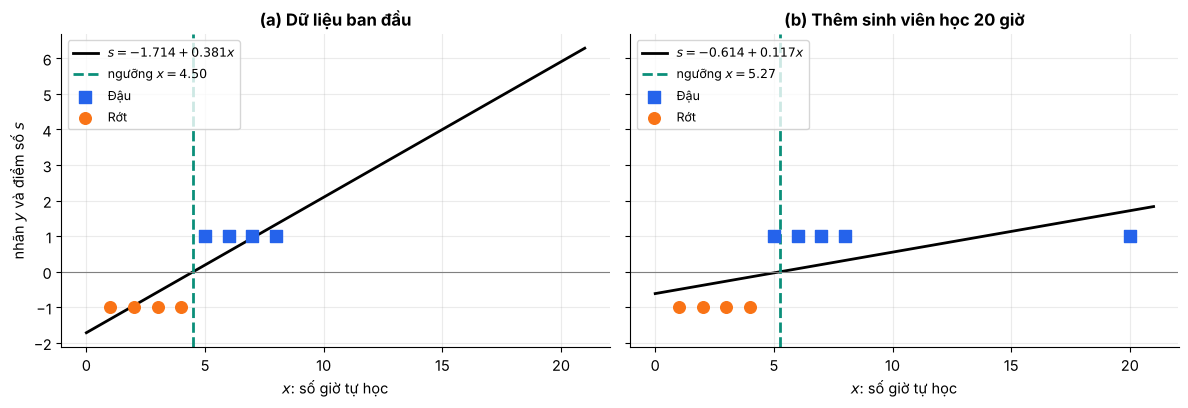

Sau khi thêm mẫu dễ: s(5 giờ) = -0.031  ->  dự đoán RỚT (sai!)


In [2]:
def hoi_quy_1d(x, y):
    """Hồi quy tuyến tính s = w0 + w1*x bằng bình phương tối thiểu (tối thiểu hóa MSE)."""
    A = np.c_[np.ones_like(x), x]                  # ghép cột 1 và cột x thành ma trận (n, 2)
    w, *_ = np.linalg.lstsq(A, y, rcond=None)      # giải min ||A w - y||^2; "*_" bỏ các giá trị trả về còn lại
    return w


x8 = np.arange(1, 9, dtype=float)
y8 = np.r_[-np.ones(4), np.ones(4)]

# Thêm một sinh viên học 20 giờ (chắc chắn đậu) để xem điều gì xảy ra.
x9 = np.r_[x8, 20.0]
y9 = np.r_[y8, 1.0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (x, y, tieu_de) in zip(axes, [(x8, y8, "(a) Dữ liệu ban đầu"), (x9, y9, "(b) Thêm sinh viên học 20 giờ")]):
    w0, w1 = hoi_quy_1d(x, y)
    xs = np.linspace(0, 21, 100)
    ax.plot(xs, w0 + w1 * xs, color="k", lw=2, label=f"$s={w0:.3f}{w1:+.3f}x$")
    nguong = -w0 / w1                              # giải s = 0
    ax.axvline(nguong, color=MAU_NHAN, ls="--", lw=2, label=f"ngưỡng $x={nguong:.2f}$")
    ax.axhline(0, color="gray", lw=0.8)
    ax.scatter(x[y == 1], y[y == 1], c=MAU_DAU, marker="s", s=70, zorder=3, label="Đậu")
    ax.scatter(x[y == -1], y[y == -1], c=MAU_ROT, s=70, zorder=3, label="Rớt")
    ax.set_title(tieu_de)
    ax.set_xlabel("$x$: số giờ tự học")
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("nhãn $y$ và điểm số $s$")
hien(fig, "h1_hoi_quy_nguong")

# Sinh viên học 5 giờ (thực tế đậu) có bị đoán sai không?
w0, w1 = hoi_quy_1d(x9, y9)
print(f"Sau khi thêm mẫu dễ: s(5 giờ) = {w0 + w1 * 5:+.3f}  ->  dự đoán {'đậu' if w0 + w1 * 5 >= 0 else 'RỚT (sai!)'}")

**Nhận xét.** Chỉ thêm một sinh viên "rất đúng" (học 20 giờ, tất nhiên đậu) mà đường hồi quy bị kéo thấp xuống, ngưỡng dịch từ 4,5 sang ≈ 5,27 và sinh viên học 5 giờ bị đoán nhầm thành rớt.

**Vì sao?** MSE muốn $s$ **càng gần +1 càng tốt**, nên điểm $s\approx 1{,}72$ của sinh viên 20 giờ vẫn bị "phạt" dù đã nằm đúng phía ngưỡng 0. Hình dưới so sánh hai kiểu phạt: MSE phạt cả khi đúng phía, còn tiêu chí ta thật sự quan tâm (đúng hay sai) thì không.

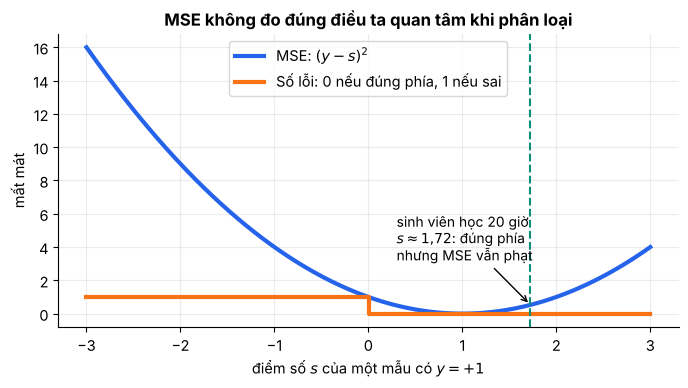

In [3]:
s = np.linspace(-3, 3, 400)
y_that = 1                                          # xét mẫu có nhãn +1
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(s, (y_that - s) ** 2, color=MAU_DAU, lw=3, label="MSE: $(y-s)^2$")
ax.step(s, (np.where(s >= 0, 1, -1) != y_that).astype(float), color=MAU_ROT, lw=3, where="post", label="Số lỗi: 0 nếu đúng phía, 1 nếu sai")
ax.axvline(1.72, color=MAU_NHAN, ls="--")
ax.annotate("sinh viên học 20 giờ\n$s\\approx1{,}72$: đúng phía\nnhưng MSE vẫn phạt", (1.72, 0.55), xytext=(0.3, 3.2),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("điểm số $s$ của một mẫu có $y=+1$")
ax.set_ylabel("mất mát")
ax.set_title("MSE không đo đúng điều ta quan tâm khi phân loại")
ax.legend()
hien(fig, "h1b_mse_vs_loi")

## 1.3. Ý tưởng: phân loại bằng một đường thẳng

Mỗi sinh viên là một điểm $(x_1,x_2)$ trên mặt phẳng (giờ học, số buổi vắng). Hai nhóm có thể được ngăn cách bằng một đường thẳng. Đó là cốt lõi của phân loại tuyến tính, và là chủ đề của mục 2.

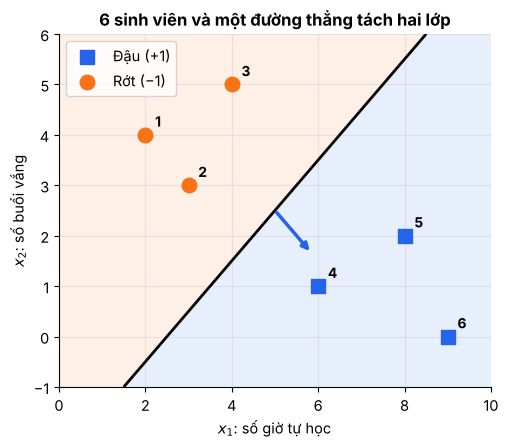

In [4]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ve_du_lieu(ax, X_sv, y_sv, co=110, nhan_so=True)
ve_duong_bien(ax, np.array([-2.5, 1.0, -1.0]), (0, 10), (-1, 6), mui_ten=True)
ax.set_title("6 sinh viên và một đường thẳng tách hai lớp")
ax.legend(loc="upper left")
hien(fig, "h2_sinh_vien_duong_thang")

---
# Mục 2. Mô hình Perceptron

## 2.1 và 2.2. Điểm số, hàm dấu và biểu diễn ma trận

Với $\mathbf{w}=[-2{,}5;\ 1;\ -1]^T$, điểm số của **cả 6 sinh viên** được tính bằng **một** phép nhân ma trận $\mathbf{s}=\mathbf{X}\mathbf{w}$.

In [5]:
w_vd = np.array([-2.5, 1.0, -1.0])

s = Xb_sv @ w_vd              # vector điểm số của 6 sinh viên: một phép nhân ma trận (6x3) @ (3,)
y_hat = np.where(s >= 0, 1, -1)   # hàm dấu với sign(0) = +1
m = y_sv * s                  # margin: nhân từng phần tử của y với s

print(f"{'SV':>3} {'s':>6} {'y_hat':>6} {'y':>4} {'m=y*s':>7}  Đúng/Sai")
for i in range(6):
    print(f"{i+1:>3} {s[i]:>6.1f} {y_hat[i]:>6d} {y_sv[i]:>4d} {m[i]:>7.1f}  {'Đúng' if m[i] > 0 else 'SAI'}")

 SV      s  y_hat    y   m=y*s  Đúng/Sai
  1   -4.5     -1   -1     4.5  Đúng
  2   -2.5     -1   -1     2.5  Đúng
  3   -3.5     -1   -1     3.5  Đúng
  4    2.5      1    1     2.5  Đúng
  5    3.5      1    1     3.5  Đúng
  6    6.5      1    1     6.5  Đúng


**Giải thích mã.**

- `Xb_sv @ w_vd`: toán tử `@` là nhân ma trận. Ma trận $6\times3$ nhân vector độ dài 3 cho vector độ dài 6, mỗi phần tử là $s_i=1\cdot w_0+x_{i1}w_1+x_{i2}w_2$. Không cần vòng lặp.
- `np.where(điều_kiện, a, b)` chọn `a` ở nơi điều kiện đúng và `b` ở nơi sai: đây là cách viết **hàm dấu** cho cả mảng.
- `y_sv * s` là nhân **từng phần tử** (không phải nhân ma trận). Nhãn ±1 làm margin $m=y\,s$ **dương khi đoán đúng**, bất kể nhãn nào.

## 2.3. Đường biên quyết định và ý nghĩa hình học của w

Tách $\mathbf{w}=[w_0;\ \tilde{\mathbf{w}}]$ với $\tilde{\mathbf{w}}=[w_1;\ w_2]$:
- $\tilde{\mathbf{w}}$ là **vector pháp tuyến**: vuông góc với đường biên, chỉ về phía $s$ tăng;
- $w_0$ quyết định **vị trí**: đổi $w_0$ thì đường biên **tịnh tiến**; đổi $\tilde{\mathbf{w}}$ thì đường biên **xoay**;
- khoảng cách từ điểm tới đường biên là $|s|/\|\tilde{\mathbf{w}}\|$.

Khoảng cách tới đường biên: [3.182 1.768 2.475 1.768 2.475 4.596]


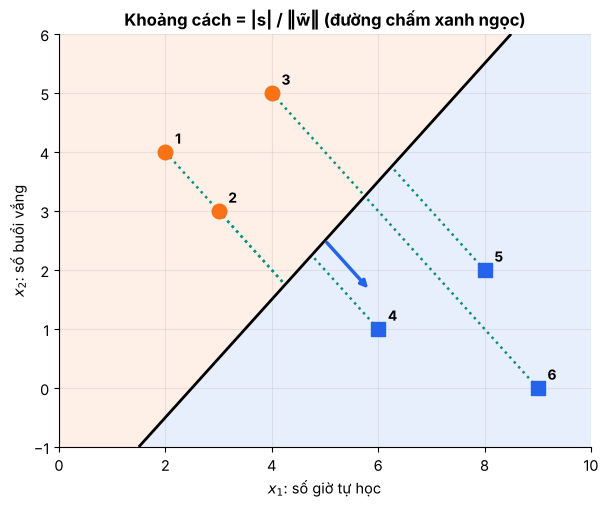

In [6]:
w_tilde = w_vd[1:]
khoang_cach = np.abs(s) / np.linalg.norm(w_tilde)      # |s| / ||w~||
print("Khoảng cách tới đường biên:", np.round(khoang_cach, 3))

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ve_du_lieu(ax, X_sv, y_sv, co=110, nhan_so=True)
ve_duong_bien(ax, w_vd, (0, 10), (-1, 6), mui_ten=True)
# Vẽ đoạn vuông góc từ mỗi điểm xuống đường biên để "thấy" khoảng cách.
n_hat = w_tilde / np.linalg.norm(w_tilde)              # vector pháp tuyến đơn vị
for p, si in zip(X_sv, s):
    chan = p - (si / np.linalg.norm(w_tilde)) * n_hat   # chân đường vuông góc trên đường biên
    ax.plot([p[0], chan[0]], [p[1], chan[1]], color=MAU_NHAN, ls=":", lw=1.8)
ax.set_title("Khoảng cách = |s| / ‖w̃‖ (đường chấm xanh ngọc)")
hien(fig, "h3_khoang_cach")

Bây giờ **tự tay xoay và dịch** đường biên để thấy vai trò của từng tham số. Hàng trên: giữ $\tilde{\mathbf{w}}$, đổi $w_0$ (đường biên trượt song song). Hàng dưới: giữ $w_0$, đổi hướng $\tilde{\mathbf{w}}$ (đường biên xoay).

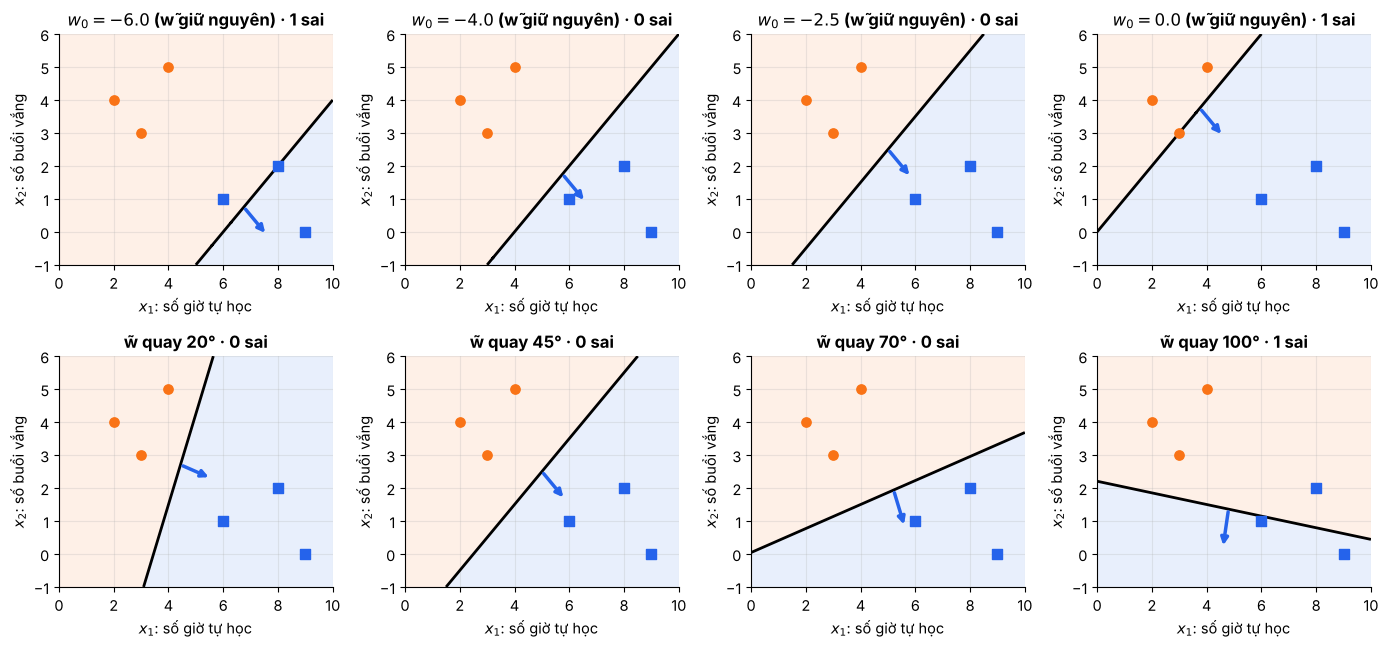

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.6))
for ax, w0 in zip(axes[0], [-6.0, -4.0, -2.5, 0.0]):
    w = np.array([w0, 1.0, -1.0])
    ve_du_lieu(ax, X_sv, y_sv, co=45)
    ve_duong_bien(ax, w, (0, 10), (-1, 6), mui_ten=True)
    sai = int((du_doan(Xb_sv, w) != y_sv).sum())
    ax.set_title(f"$w_0={w0}$ (w̃ giữ nguyên) · {sai} sai")
for ax, goc in zip(axes[1], [20, 45, 70, 100]):
    r = np.deg2rad(goc)
    w_t = np.array([np.cos(r), -np.sin(r)])              # w~ có độ dài 1, xoay theo góc "goc"
    # chọn w0 để đường biên luôn đi qua điểm (4, 1.5) nằm giữa hai nhóm: w0 = -(w1*4 + w2*1.5)
    w = np.array([-(w_t[0] * 4 + w_t[1] * 1.5), w_t[0], w_t[1]])
    ve_du_lieu(ax, X_sv, y_sv, co=45)
    ve_duong_bien(ax, w, (0, 10), (-1, 6), mui_ten=True)
    sai = int((du_doan(Xb_sv, w) != y_sv).sum())
    ax.set_title(f"w̃ quay {goc}° · {sai} sai")
hien(fig, "h4_tinh_tien_xoay")

### Hai tính chất cần nhớ về hàm dấu
1. **Nhân w với một hằng số dương không đổi dự đoán** (chỉ đổi độ lớn của $s$). Vì vậy một đường biên có vô số $\mathbf{w}$ biểu diễn.
2. **sign(0) = +1** là một quy ước để mô hình luôn trả ra đúng một nhãn, kể cả với điểm nằm *đúng trên* đường biên.

In [8]:
print("Nhân w với 1, 3, 100 -> nhãn dự đoán không đổi:")
for k in [1, 3, 100]:
    print(f"  k = {k:>3}: ", du_doan(Xb_sv, k * w_vd))

# điểm nằm đúng trên đường biên x2 = x1 - 2.5, ví dụ (4, 1.5)
diem_tren_bien = np.array([[1.0, 4.0, 1.5]])
print("Điểm trên biên: s =", (diem_tren_bien @ w_vd)[0], "-> nhãn", du_doan(diem_tren_bien, w_vd)[0], "(do quy ước sign(0)=+1)")

Nhân w với 1, 3, 100 -> nhãn dự đoán không đổi:
  k =   1:  [-1 -1 -1  1  1  1]
  k =   3:  [-1 -1 -1  1  1  1]
  k = 100:  [-1 -1 -1  1  1  1]
Điểm trên biên: s = 0.0 -> nhãn 1 (do quy ước sign(0)=+1)


---
# Mục 3. Huấn luyện mô hình Perceptron

Khung quen thuộc: **Mô hình** → **Hàm mất mát** → **Thuật toán tối ưu**.

## 3.2. Hàm mất mát của Perceptron

Số lỗi 0–1 là hàm bậc thang: đạo hàm bằng 0 gần như mọi nơi nên Gradient Descent không có "hướng" để đi. **Mất mát Perceptron** là
$$\ell_i=\max(0,\,-m_i),\qquad J(\mathbf{w})=\sum_i \ell_i$$
bằng 0 nếu mẫu đúng, và bằng **độ lớn của margin âm** nếu mẫu sai: sai càng nặng, phạt càng lớn, và đồ thị có độ dốc.

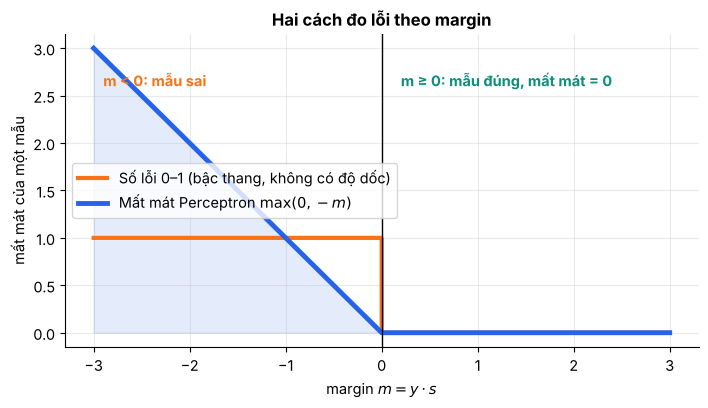

In [9]:
m_axis = np.linspace(-3, 3, 601)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(m_axis, (m_axis < 0).astype(float), color=MAU_ROT, lw=3, drawstyle="steps-post", label="Số lỗi 0–1 (bậc thang, không có độ dốc)")
ax.plot(m_axis, np.maximum(0, -m_axis), color=MAU_DAU, lw=3.5, label="Mất mát Perceptron $\\max(0,-m)$")
ax.axvline(0, color="k", lw=1)
ax.fill_between(m_axis[m_axis < 0], 0, np.maximum(0, -m_axis[m_axis < 0]), color=MAU_DAU, alpha=0.12)
ax.text(-2.9, 2.6, "m < 0: mẫu sai", color=MAU_ROT, fontweight="bold")
ax.text(0.2, 2.6, "m ≥ 0: mẫu đúng, mất mát = 0", color=MAU_NHAN, fontweight="bold")
ax.set_xlabel("margin $m=y\\cdot s$")
ax.set_ylabel("mất mát của một mẫu")
ax.set_title("Hai cách đo lỗi theo margin")
ax.legend(loc="center left")
hien(fig, "h5_mat_mat")


def tong_mat_mat(Xb, y, w):
    """J(w) = tổng các max(0, -m_i)."""
    m = y * (Xb @ w)                    # margin của mọi mẫu
    return np.maximum(0, -m).sum()      # np.maximum so sánh từng phần tử với 0

**Giải thích mã.** `np.maximum(0, -m)` so sánh *từng phần tử* của `-m` với 0 và lấy số lớn hơn. Nó khác `np.max` (tìm một giá trị lớn nhất của cả mảng). Kết quả là một vector mất mát $\ell_i$ cho từng mẫu, rồi `.sum()` cộng lại thành $J$.

### Ví dụ số: bộ tham số càng tệ thì J càng lớn

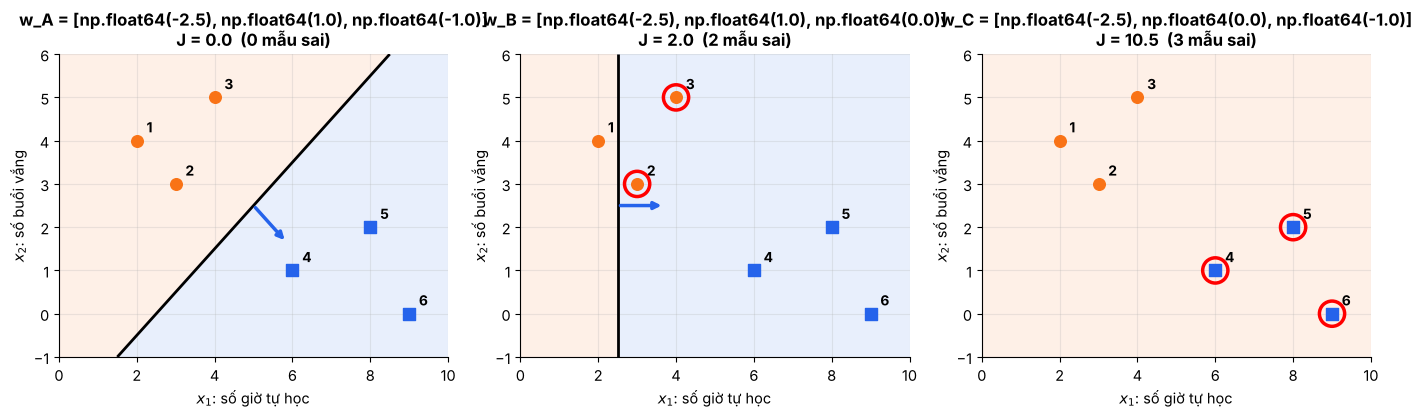

In [10]:
cac_w = {"w_A": np.array([-2.5, 1.0, -1.0]), "w_B": np.array([-2.5, 1.0, 0.0]), "w_C": np.array([-2.5, 0.0, -1.0])}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, (ten, w) in zip(axes, cac_w.items()):
    m = y_sv * (Xb_sv @ w)
    ve_du_lieu(ax, X_sv, y_sv, co=70, nhan_so=True)
    ve_duong_bien(ax, w, (0, 10), (-1, 6), mui_ten=True)
    sai = np.where(m <= 0)[0]
    ax.scatter(*X_sv[sai].T, s=330, facecolors="none", edgecolors="red", linewidths=2.5, zorder=4)   # khoanh tròn mẫu sai
    ax.set_title(f"{ten} = {list(w)}\nJ = {tong_mat_mat(Xb_sv, y_sv, w):.1f}  ({len(sai)} mẫu sai)")
hien(fig, "h6_J_ba_bo_tham_so")

Có thể xem **J như một "địa hình"** theo $(w_1,w_2)$ (giữ $w_0=-2{,}5$). Vùng trắng/xanh là nơi $J=0$ (mọi mẫu đúng), càng ra xa càng đỏ. Huấn luyện chính là **đi xuống dốc** về vùng đó.

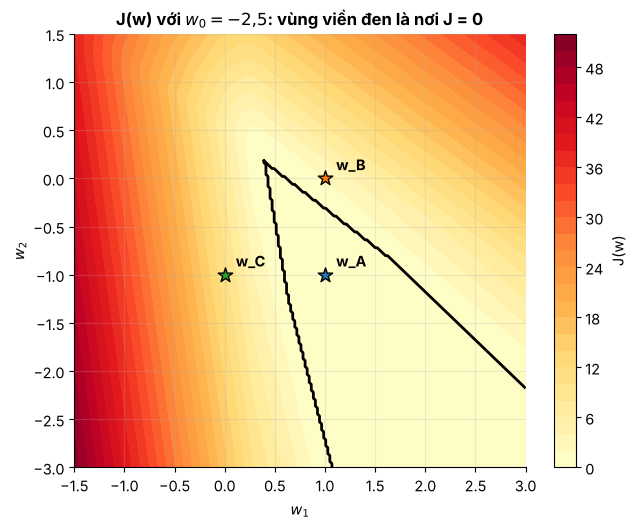

In [11]:
g1 = np.linspace(-1.5, 3.0, 220)
g2 = np.linspace(-3.0, 1.5, 220)
G1, G2 = np.meshgrid(g1, g2)
J = np.zeros_like(G1)
for a in range(G1.shape[0]):               # duyệt từng điểm lưới (đủ nhanh vì chỉ có 220x220)
    for b in range(G1.shape[1]):
        J[a, b] = tong_mat_mat(Xb_sv, y_sv, np.array([-2.5, G1[a, b], G2[a, b]]))

fig, ax = plt.subplots(figsize=(6.6, 5.4))
cs = ax.contourf(G1, G2, J, levels=25, cmap="YlOrRd")
ax.contour(G1, G2, J, levels=[1e-9], colors="k", linewidths=2)      # biên vùng J = 0
plt.colorbar(cs, ax=ax, label="J(w)")
for ten, w in cac_w.items():
    ax.scatter(w[1], w[2], s=120, marker="*", edgecolors="k", zorder=5)
    ax.annotate(ten, (w[1], w[2]), textcoords="offset points", xytext=(8, 6), fontweight="bold")
ax.set_xlabel("$w_1$")
ax.set_ylabel("$w_2$")
ax.set_title("J(w) với $w_0=-2{,}5$: vùng viền đen là nơi J = 0")
hien(fig, "h7_dia_hinh_J")

## 3.3. Quy tắc cập nhật

Gradient của mất mát một mẫu **sai** là $\nabla\ell_i=-y_i\mathbf{x}_i^T$ (mẫu đúng: bằng 0). Một bước Gradient Descent với **một mẫu**:

$$\mathbf{w}\leftarrow\mathbf{w}+\eta\,y_i\,\mathbf{x}_i^T\quad\text{nếu } y_i\mathbf{x}_i\mathbf{w}\le0$$

- $y_i=+1$ (bỏ sót) → **cộng** $\mathbf{x}_i^T$ vào $\mathbf{w}$: kéo $\mathbf{w}$ lại gần $\mathbf{x}_i$.
- $y_i=-1$ (báo nhầm) → **trừ** $\mathbf{x}_i^T$: đẩy $\mathbf{w}$ ra xa $\mathbf{x}_i$.

Và có một kết quả đẹp: sau khi cập nhật, margin của chính mẫu đó **tăng thêm đúng** $\eta\|\mathbf{x}_i\|^2$. Ta kiểm chứng bằng một lần cập nhật thật (sinh viên 2 khi $\mathbf{w}=[0;4;-3]^T$).

Trước: s = +3.0, m = -3.0  ->  cần cập nhật
w mới = [-1.  1. -6.]
Sau  : m = +16.0;  công thức m + η‖x‖² = -3.0 + 19 = +16.0  (khớp)


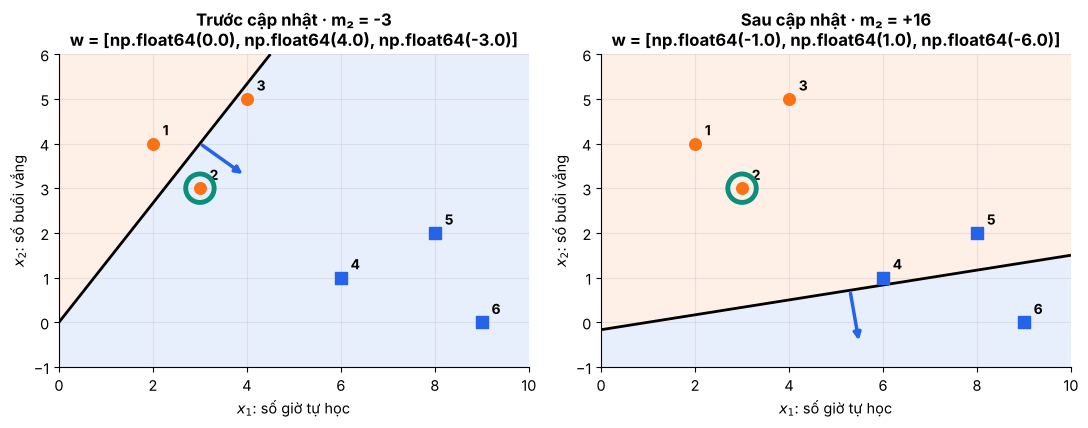

In [12]:
eta = 1.0
w_truoc = np.array([0.0, 4.0, -3.0])
i = 1                                                   # sinh viên 2 (chỉ số 1)
x_i, y_i = Xb_sv[i], y_sv[i]
m_truoc = y_i * (x_i @ w_truoc)
print(f"Trước: s = {x_i @ w_truoc:+.1f}, m = {m_truoc:+.1f}  ->  {'cần cập nhật' if m_truoc <= 0 else 'giữ nguyên'}")

w_sau = w_truoc + eta * y_i * x_i                       # QUY TẮC CẬP NHẬT
m_sau = y_i * (x_i @ w_sau)
print(f"w mới = {w_sau}")
print(f"Sau  : m = {m_sau:+.1f};  công thức m + η‖x‖² = {m_truoc:+.1f} + {eta * (x_i @ x_i):.0f} = {m_truoc + eta * (x_i @ x_i):+.1f}  (khớp)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, w, tieu in zip(axes, [w_truoc, w_sau], [f"Trước cập nhật · m₂ = {m_truoc:+.0f}", f"Sau cập nhật · m₂ = {m_sau:+.0f}"]):
    ve_du_lieu(ax, X_sv, y_sv, co=70, nhan_so=True)
    ve_duong_bien(ax, w, (0, 10), (-1, 6), mui_ten=True)
    ax.scatter(*X_sv[i], s=420, facecolors="none", edgecolors=MAU_NHAN, linewidths=3.5, zorder=4)
    ax.set_title(tieu + f"\nw = {list(np.round(w, 1))}")
hien(fig, "h8_mot_lan_cap_nhat")

Sinh viên 2 (vòng xanh ngọc) trước đó nằm sai phía; sau một lần cập nhật đường biên **xoay** để mẫu này về đúng phía. Lưu ý: một lần cập nhật chỉ đảm bảo cải thiện mẫu đang xét, có thể làm các mẫu khác tệ đi. Vì vậy phải lặp.

## 3.4 và 3.5. Thuật toán qua từng bước (tính tay → chạy máy)

Khởi tạo $\mathbf{w}=\mathbf{0}$, $\eta=1$, duyệt 1→6, lặp theo **epoch** (mỗi epoch là một lượt qua mọi mẫu), dừng khi một epoch không có cập nhật nào.

In [13]:
w_cuoi, lich_su, quy_dao = huan_luyen(Xb_sv, y_sv, eta=1.0)
print("w cuối              :", w_cuoi)
print("Số cập nhật mỗi epoch:", lich_su, " (epoch cuối = 0 -> hội tụ)")
print("y_hat               :", du_doan(Xb_sv, w_cuoi))
print("margin m            :", y_sv * (Xb_sv @ w_cuoi))
print("w sau từng lần cập nhật:")
print(np.array(quy_dao))

w cuối              : [-1.  4. -8.]
Số cập nhật mỗi epoch: [2, 2, 1, 0]  (epoch cuối = 0 -> hội tụ)
y_hat               : [-1 -1 -1  1  1  1]
margin m            : [25. 13. 25. 15. 15. 35.]
w sau từng lần cập nhật:
[[-1. -2. -4.]
 [ 0.  4. -3.]
 [-1.  1. -6.]
 [ 0.  7. -5.]
 [-1.  4. -8.]]


Kết quả khớp ví dụ tính tay: $\mathbf{w}=[-1;\,4;\,-8]^T$, số cập nhật là 2, 2, 1, 0.

Hình dưới là **phim chụp từng khung**: đường biên sau mỗi lần cập nhật (vòng xanh ngọc là mẫu vừa được sửa).

Lần Epoch  Mẫu  s trước      m   w sau
  1     1    1        0      0   [-1. -2. -4.]
  2     1    4      -17    -17   [ 0.  4. -3.]
  3     2    2        3     -3   [-1.  1. -6.]
  4     2    4       -1     -1   [ 0.  7. -5.]
  5     3    2        6     -6   [-1.  4. -8.]


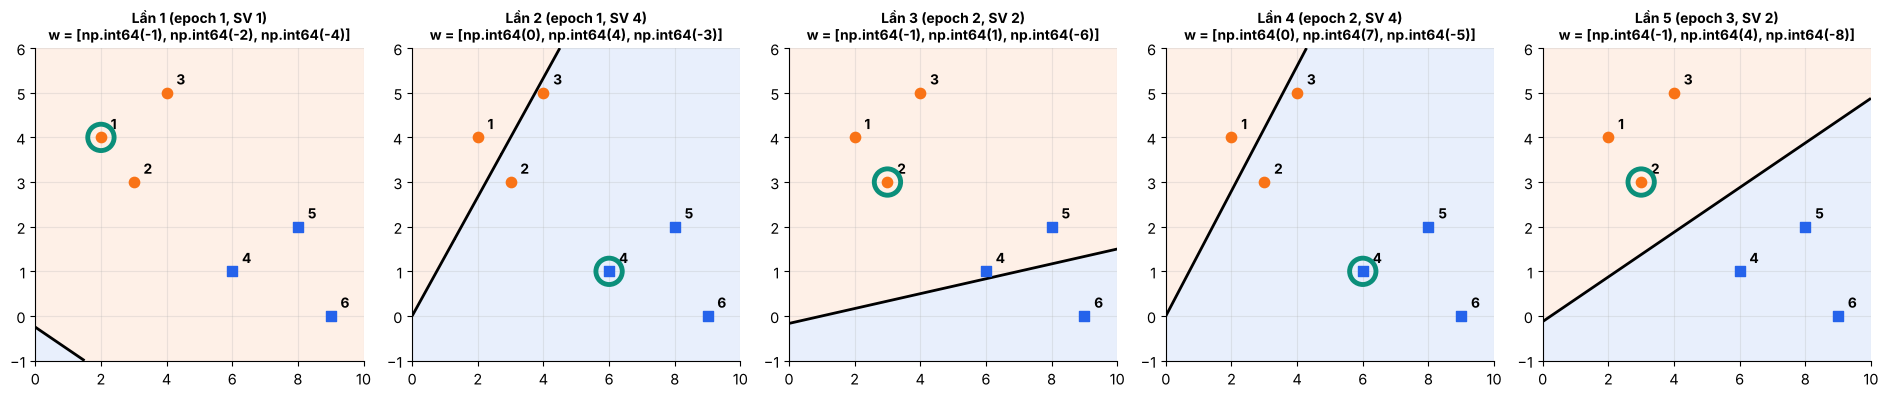

In [14]:
# Cần biết mẫu nào được cập nhật ở mỗi lần: chạy lại và ghi thêm chỉ số mẫu.
def huan_luyen_ghi_vet(Xb, y, eta=1.0, t_max=100):
    w = np.zeros(Xb.shape[1])
    vet = []                      # mỗi phần tử: (epoch, chỉ số mẫu, s trước, m trước, w sau)
    for epoch in range(1, t_max + 1):
        c = 0
        for i in range(len(y)):
            s_ = Xb[i] @ w
            if y[i] * s_ <= 0:
                w = w + eta * y[i] * Xb[i]
                vet.append((epoch, i, s_ + 0.0, y[i] * s_ + 0.0, w.copy()))  # '+ 0.0' để tránh in ra -0
                c += 1
        if c == 0:
            break
    return vet


vet = huan_luyen_ghi_vet(Xb_sv, y_sv)
print(f"{'Lần':>3} {'Epoch':>5} {'Mẫu':>4} {'s trước':>8} {'m':>6}   w sau")
for k, (e, i, s_, m_, w) in enumerate(vet, 1):
    print(f"{k:>3} {e:>5} {i+1:>4} {s_:>8.0f} {m_:>6.0f}   {w}")

fig, axes = plt.subplots(1, 5, figsize=(19, 4.1))
for k, (ax, (e, i, s_, m_, w)) in enumerate(zip(axes, vet), 1):
    ve_du_lieu(ax, X_sv, y_sv, co=55, nhan_so=True)
    ve_duong_bien(ax, w, (0, 10), (-1, 6))
    ax.scatter(*X_sv[i], s=360, facecolors="none", edgecolors=MAU_NHAN, linewidths=3.5, zorder=4)
    ax.set_title(f"Lần {k} (epoch {e}, SV {i+1})\nw = {list(w.astype(int))}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
hien(fig, "h9_nam_lan_cap_nhat")

### Cuộc "giằng co" của các margin
Bảng nhiệt dưới đây cho thấy margin của 6 sinh viên (hàng) sau mỗi lần cập nhật (cột). **Đỏ/cam = margin ≤ 0 (sai)**, xanh = đúng. Mỗi lần cập nhật cứu một mẫu nhưng đôi khi làm mẫu khác sai lại (ví dụ SV 2 và SV 4 bị sửa nhiều lần), cho đến khi cả cột đều xanh.

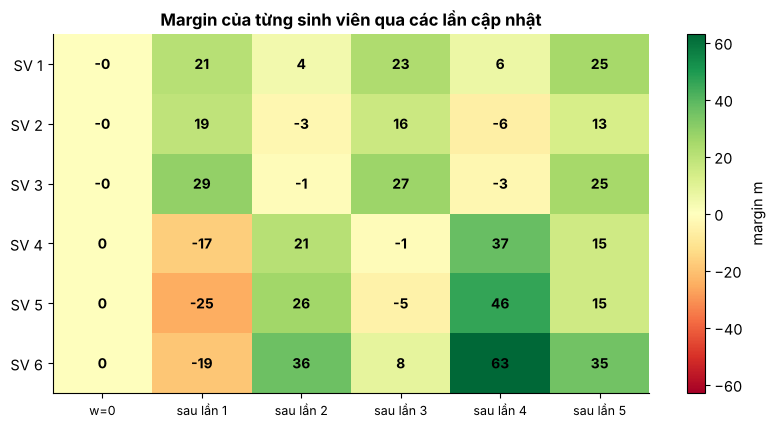

In [15]:
cac_w = [np.zeros(3)] + [v[4] for v in vet]
M = np.array([y_sv * (Xb_sv @ w) for w in cac_w]).T          # ma trận margin: hàng = sinh viên, cột = thời điểm
fig, ax = plt.subplots(figsize=(8.2, 4.4))
lim = np.abs(M).max()
im = ax.imshow(M, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
for a in range(M.shape[0]):
    for b in range(M.shape[1]):
        ax.text(b, a, f"{M[a, b]:.0f}", ha="center", va="center", fontsize=10, fontweight="bold")
ax.set_xticks(range(M.shape[1]))
ax.set_xticklabels(["w=0"] + [f"sau lần {k}" for k in range(1, len(vet) + 1)], fontsize=9)
ax.set_yticks(range(6))
ax.set_yticklabels([f"SV {i}" for i in range(1, 7)])
ax.grid(False)
ax.set_title("Margin của từng sinh viên qua các lần cập nhật")
plt.colorbar(im, ax=ax, label="margin m")
hien(fig, "h10_margin_heatmap")

**Giải thích mã.** `M = np.array([... for w in cac_w]).T`: với mỗi $\mathbf{w}$ ta tính vector margin 6 phần tử, xếp chúng thành một mảng (6 lần × 6 mẫu) rồi `.T` (chuyển vị) để hàng là sinh viên, cột là thời điểm. `imshow` biến mảng số thành ảnh màu.

## 3.6. Tốc độ học η
Với khởi tạo $\mathbf{w}=\mathbf{0}$, η chỉ **co giãn** $\mathbf{w}$ mà không đổi bộ phân loại. Với khởi tạo khác 0, η có ảnh hưởng.

In [16]:
print("Khởi tạo w = 0:")
for eta in [0.1, 1, 10]:
    w, ls, qd = huan_luyen(Xb_sv, y_sv, eta=eta)
    print(f"  η = {eta:>4}: {len(qd)} lần cập nhật, w = {np.round(w, 2)}, nhãn dự đoán = {du_doan(Xb_sv, w)}")
print("Khởi tạo w = [1, 1, 1]:")
for eta in [0.1, 1, 10]:
    w, ls, qd = huan_luyen(Xb_sv, y_sv, eta=eta, w0=[1, 1, 1])
    print(f"  η = {eta:>4}: {len(qd)} lần cập nhật, w = {np.round(w, 2)}")

Khởi tạo w = 0:
  η =  0.1: 5 lần cập nhật, w = [-0.1  0.4 -0.8], nhãn dự đoán = [-1 -1 -1  1  1  1]
  η =    1: 5 lần cập nhật, w = [-1.  4. -8.], nhãn dự đoán = [-1 -1 -1  1  1  1]
  η =   10: 5 lần cập nhật, w = [-10.  40. -80.], nhãn dự đoán = [-1 -1 -1  1  1  1]
Khởi tạo w = [1, 1, 1]:
  η =  0.1: 6 lần cập nhật, w = [ 0.6  0.2 -0.8]
  η =    1: 3 lần cập nhật, w = [ 0.  3. -6.]
  η =   10: 5 lần cập nhật, w = [ -9.  41. -79.]


---
# Mục 4. Phân tích cơ chế học của Perceptron

## 4.1. Thứ tự duyệt mẫu và giá trị khởi tạo
Vì Perceptron cập nhật **ngay** sau mỗi mẫu, thứ tự duyệt ảnh hưởng đến kết quả. Ta chạy **cả 6! = 720 thứ tự**.

Số thứ tự theo số lần cập nhật: {2: 80, 3: 244, 4: 40, 5: 356}
Số bộ w cuối cùng khác nhau   : 20


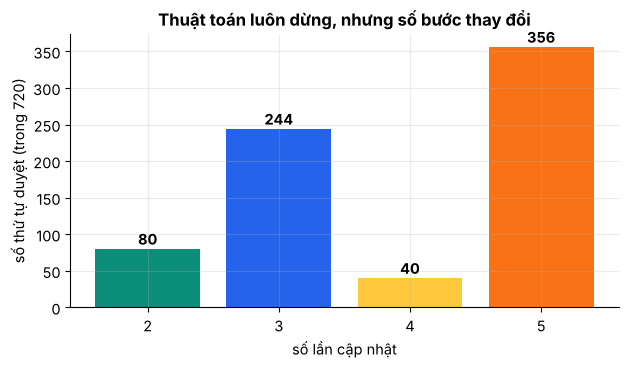

In [17]:
ket_qua = Counter()          # đếm có bao nhiêu thứ tự cần 2, 3, 4, 5 lần cập nhật
cac_w_cuoi = set()           # tập các w cuối cùng khác nhau (set tự loại trùng)
for hoan_vi in itertools.permutations(range(6)):         # sinh lần lượt cả 720 hoán vị của 0..5
    w, ls, qd = huan_luyen(Xb_sv, y_sv, thu_tu=hoan_vi)
    ket_qua[len(qd)] += 1
    cac_w_cuoi.add(tuple(w))                             # list không băm được, nên đổi sang tuple

print("Số thứ tự theo số lần cập nhật:", dict(sorted(ket_qua.items())))
print("Số bộ w cuối cùng khác nhau   :", len(cac_w_cuoi))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ks = sorted(ket_qua)
ax.bar([str(k) for k in ks], [ket_qua[k] for k in ks], color=[MAU_NHAN, MAU_DAU, "#FFC83D", MAU_ROT])
for j, k in enumerate(ks):
    ax.text(j, ket_qua[k] + 6, str(ket_qua[k]), ha="center", fontweight="bold")
ax.set_xlabel("số lần cập nhật")
ax.set_ylabel("số thứ tự duyệt (trong 720)")
ax.set_title("Thuật toán luôn dừng, nhưng số bước thay đổi")
hien(fig, "h11_720_thu_tu")

**Giải thích mã.** `itertools.permutations(range(6))` sinh lần lượt mọi cách sắp xếp 6 chỉ số. `thu_tu=hoan_vi` báo cho `huan_luyen` duyệt mẫu theo thứ tự đó. `Counter` là dictionary đếm; `set` chỉ giữ các phần tử khác nhau, nhờ vậy `len(cac_w_cuoi)` cho biết có bao nhiêu nghiệm khác nhau. Mọi thứ tự đều **đúng 100% trên dữ liệu huấn luyện**, nhưng có nhiều đường biên khác nhau, và chúng **dự đoán khác nhau** với dữ liệu mới:

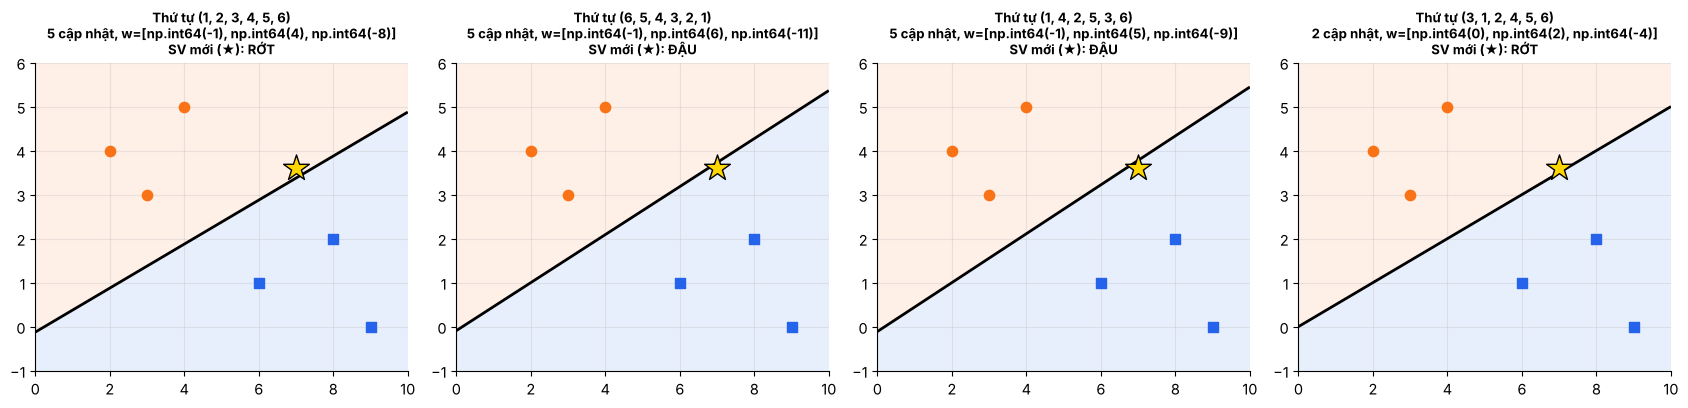

In [18]:
cac_thu_tu = [(1, 2, 3, 4, 5, 6), (6, 5, 4, 3, 2, 1), (1, 4, 2, 5, 3, 6), (3, 1, 2, 4, 5, 6)]
sv_moi = np.array([[1.0, 7.0, 3.6]])                     # sinh viên mới: học 7 giờ, vắng 3,6 buổi
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, tt in zip(axes, cac_thu_tu):
    w, ls, qd = huan_luyen(Xb_sv, y_sv, thu_tu=[t - 1 for t in tt])
    ve_du_lieu(ax, X_sv, y_sv, co=55)
    ve_duong_bien(ax, w, (0, 10), (-1, 6))
    ax.scatter(7, 3.6, marker="*", s=380, c="gold", edgecolors="k", zorder=5)
    nhan = "ĐẬU" if du_doan(sv_moi, w)[0] > 0 else "RỚT"
    ax.set_title(f"Thứ tự {tt}\n{len(qd)} cập nhật, w={list(w.astype(int))}\nSV mới (★): {nhan}", fontsize=9.5)
    ax.set_xlabel("")
    ax.set_ylabel("")
hien(fig, "h12_bon_duong_bien")

Cùng dữ liệu huấn luyện nhưng sinh viên mới (★) bị đoán **rớt** hoặc **đậu** tuỳ đường biên. Perceptron không có cơ chế chọn đường nào "tốt hơn": nó dừng ngay khi hết mẫu sai. Muốn đường biên *tốt nhất* (cách đều hai lớp) cần các mô hình khác như SVM.

**Khởi tạo** cũng ảnh hưởng: khởi tạo càng gần một nghiệm đúng thì càng ít cập nhật.

In [19]:
for w0 in ([0, 0, 0], [-2, 1, 0], [1, 1, 1], [0, -1, 0], [-2.5, 1, -1]):
    w, ls, qd = huan_luyen(Xb_sv, y_sv, w0=w0)
    print(f"w khởi tạo = {str(w0):>14}  ->  {len(qd)} lần cập nhật, w cuối = {w}")

w khởi tạo =      [0, 0, 0]  ->  5 lần cập nhật, w cuối = [-1.  4. -8.]
w khởi tạo =     [-2, 1, 0]  ->  3 lần cập nhật, w cuối = [-3.  2. -6.]
w khởi tạo =      [1, 1, 1]  ->  3 lần cập nhật, w cuối = [ 0.  3. -6.]
w khởi tạo =     [0, -1, 0]  ->  5 lần cập nhật, w cuối = [-1.  3. -8.]
w khởi tạo =  [-2.5, 1, -1]  ->  0 lần cập nhật, w cuối = [-2.5  1.  -1. ]


## 4.2. Điều kiện hội tụ: định lý Novikoff

**Định lý.** Nếu tồn tại $\mathbf{w}^*$ với $\|\mathbf{w}^*\|=1$ và $\gamma>0$ sao cho $y_i\mathbf{x}_i\mathbf{w}^*\ge\gamma$ với mọi $i$, thì Perceptron (khởi tạo 0) thực hiện **không quá** $R^2/\gamma^2$ lần cập nhật, với $R=\max_i\|\mathbf{x}_i\|$.

Ý tưởng chứng minh gói trong **hai bất đẳng thức**: sau $k$ lần cập nhật
- hình chiếu của $\mathbf{w}_k$ lên $\mathbf{w}^*$ **tăng tuyến tính**: $(\mathbf{w}^*)^T\mathbf{w}_k\ge k\eta\gamma$;
- độ dài $\|\mathbf{w}_k\|$ **chỉ tăng cỡ √k**: $\|\mathbf{w}_k\|^2\le k\eta^2R^2$.

Hình chiếu không thể dài hơn chính vector, nên $k$ không thể tăng mãi. Ta kiểm chứng bằng số trên dữ liệu 6 sinh viên.

In [20]:
w_sao = np.array([-1.0, 2.0, -4.0]) / np.sqrt(21)         # một w* có độ dài 1
m_sao = y_sv * (Xb_sv @ w_sao)
gamma = m_sao.min()                                       # γ = margin nhỏ nhất
R = np.linalg.norm(Xb_sv, axis=1).max()                   # R = độ dài lớn nhất của các x_i
print(f"‖w*‖ = {np.linalg.norm(w_sao):.3f},  γ = {gamma:.3f},  R² = {R**2:.0f}")
print(f"Cận trên R²/γ² = {R**2 / gamma**2:.1f}  ->  tối đa {int(R**2 // gamma**2)} lần cập nhật")
print(f"Thực tế (720 thứ tự): nhiều nhất {max(ket_qua)} lần")

‖w*‖ = 1.000,  γ = 1.528,  R² = 82
Cận trên R²/γ² = 35.1  ->  tối đa 35 lần cập nhật
Thực tế (720 thứ tự): nhiều nhất 5 lần


**Giải thích mã.** `np.linalg.norm(Xb_sv, axis=1)` tính độ dài (chuẩn Euclid) **theo từng hàng** nên cho 6 số; `axis=1` nghĩa là "gộp dọc theo cột, mỗi hàng ra một kết quả". Cận 35 là *bảo đảm an toàn* chứ không phải dự đoán chính xác: thực tế chỉ cần tối đa 5 lần.

### Khoảng cách giữa hai lớp quyết định tốc độ học
Cận $R^2/\gamma^2$ cho thấy: hai lớp **càng xa nhau** ($\gamma$ lớn) thì **càng ít** lần cập nhật. Thí nghiệm: hai lớp, mỗi lớp 50 điểm đều trong hình vuông $4\times4$ (đối xứng quanh gốc tọa độ), cách nhau một khoảng trống $g$ theo $x_1$.

Khoảng trống g          : [0.25, 0.5, 1, 2, 4, 8]
Số lần cập nhật trung bình: [10.4  5.5  2.9  1.6  1.   1. ]


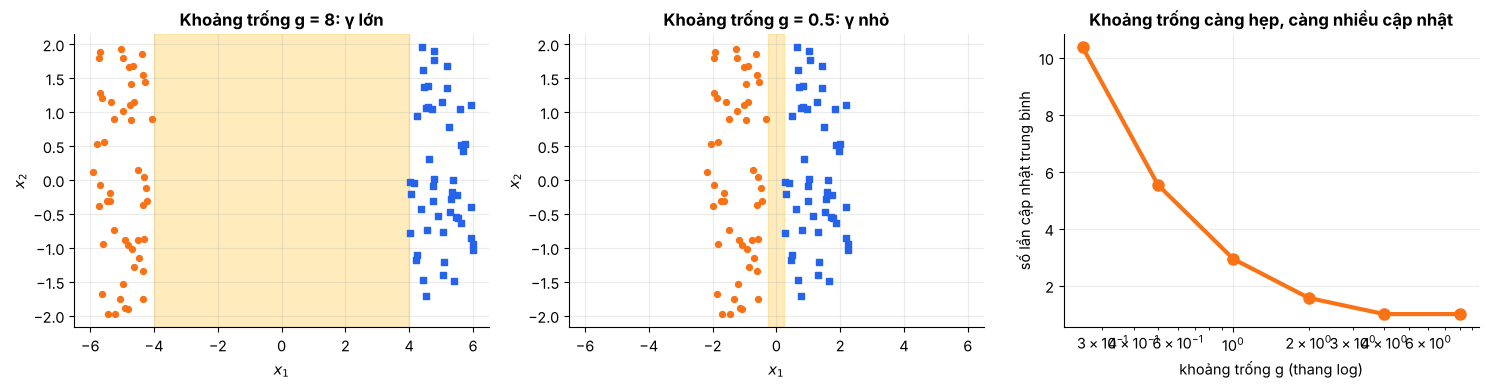

In [21]:
def du_lieu_hai_o_vuong(g, rng, n=50):
    """Hai hình vuông 4x4 đối xứng quanh gốc, cách nhau khoảng trống g dọc theo trục x1."""
    trai = rng.uniform([-2 - g / 2, -2], [-g / 2, 2], size=(n, 2))
    phai = rng.uniform([g / 2, -2], [2 + g / 2, 2], size=(n, 2))
    return np.vstack([trai, phai]), np.r_[-np.ones(n), np.ones(n)]


rng = np.random.default_rng(0)
cac_g = [0.25, 0.5, 1, 2, 4, 8]
tb = []
for g in cac_g:
    dem = []
    for _ in range(30):                                   # 30 bộ dữ liệu ngẫu nhiên cho mỗi g
        X, y = du_lieu_hai_o_vuong(g, rng)
        _, _, qd = huan_luyen(them_bias(X), y)
        dem.append(len(qd))
    tb.append(np.mean(dem))
print("Khoảng trống g          :", cac_g)
print("Số lần cập nhật trung bình:", np.round(tb, 1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, g in zip(axes[:2], [8, 0.5]):
    X, y = du_lieu_hai_o_vuong(g, np.random.default_rng(1))
    ve_du_lieu(ax, X, y, co=18)
    ax.axvspan(-g / 2, g / 2, color="#FFC83D", alpha=0.35)
    ax.set_title(f"Khoảng trống g = {g}: γ {'lớn' if g > 1 else 'nhỏ'}")
    ax.set_xlim(-6.5, 6.5)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
axes[2].plot(cac_g, tb, "o-", color=MAU_ROT, lw=3, ms=8)
axes[2].set_xscale("log")
axes[2].set_xlabel("khoảng trống g (thang log)")
axes[2].set_ylabel("số lần cập nhật trung bình")
axes[2].set_title("Khoảng trống càng hẹp, càng nhiều cập nhật")
hien(fig, "h13_khoang_trong")

## 4.3. Khi không hội tụ: bài toán XOR
XOR cho kết quả +1 khi hai đầu vào **khác nhau**. Bốn điểm nằm ở bốn đỉnh hình vuông, hai điểm cùng lớp ở **hai đỉnh đối diện**, nên không đường thẳng nào tách được.

In [22]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([-1, 1, 1, -1])
Xb_xor = them_bias(X_xor)

w, ls_xor, qd = huan_luyen(Xb_xor, y_xor, t_max=10)
print("Số cập nhật mỗi epoch trên XOR:", ls_xor, " (không bao giờ về 0)")
print("w sau từng lần cập nhật trong epoch 1:")
print(np.array(qd[:4]))
print("-> sau 4 lần w quay về [0, 0, 0]: trạng thái ban đầu, nên epoch sau lặp lại y hệt.")

Số cập nhật mỗi epoch trên XOR: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]  (không bao giờ về 0)
w sau từng lần cập nhật trong epoch 1:
[[-1.  0.  0.]
 [ 0.  0.  1.]
 [ 1.  1.  1.]
 [ 0.  0.  0.]]
-> sau 4 lần w quay về [0, 0, 0]: trạng thái ban đầu, nên epoch sau lặp lại y hệt.


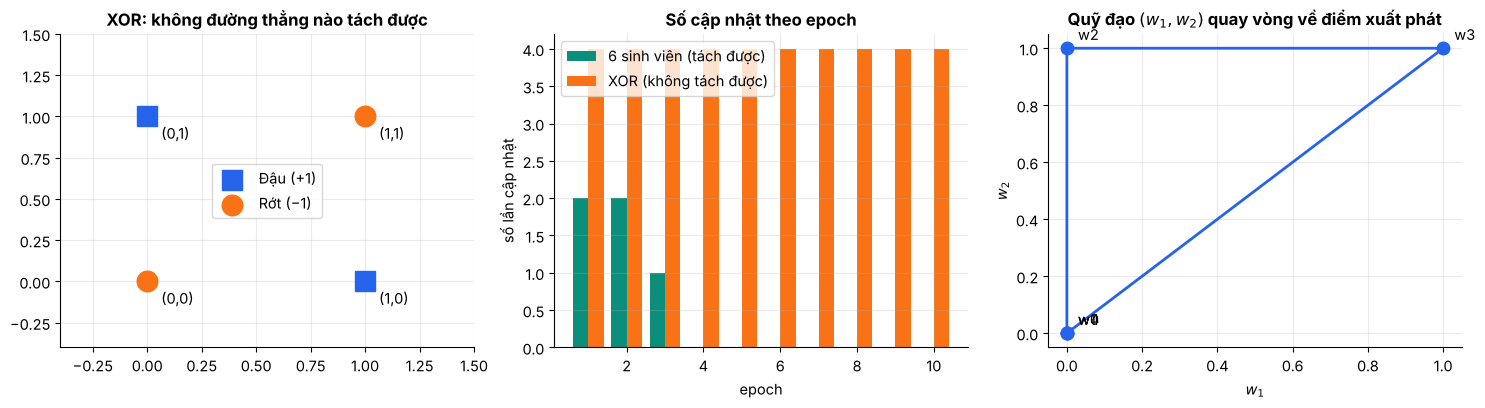

In [23]:
# So sánh: dữ liệu tách được (sinh viên) hội tụ về 0, XOR thì luôn là 4.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
ve_du_lieu(ax, X_xor, y_xor, co=220)
for p, (a, b) in zip(X_xor, [(0, 0), (0, 1), (1, 0), (1, 1)]):
    ax.annotate(f"({a},{b})", p, textcoords="offset points", xytext=(10, -16))
ax.set_xlim(-0.4, 1.5)
ax.set_ylim(-0.4, 1.5)
ax.set_title("XOR: không đường thẳng nào tách được")
ax.legend(loc="center")

ax = axes[1]
ep_sv = np.arange(1, len(lich_su) + 1)
ep_xor = np.arange(1, 11)
ax.bar(ep_sv - 0.2, lich_su, width=0.4, color=MAU_NHAN, label="6 sinh viên (tách được)")
ax.bar(ep_xor + 0.2, ls_xor, width=0.4, color=MAU_ROT, label="XOR (không tách được)")
ax.set_xlabel("epoch")
ax.set_ylabel("số lần cập nhật")
ax.set_title("Số cập nhật theo epoch")
ax.legend()

ax = axes[2]
quy = np.array([[0, 0, 0]] + [v for v in qd[:4]])
ax.plot(quy[:, 1], quy[:, 2], "o-", color=MAU_DAU, lw=2, ms=9)
for k, (a, b) in enumerate(zip(quy[:, 1], quy[:, 2])):
    ax.annotate(f"w{k}", (a, b), textcoords="offset points", xytext=(8, 6))
ax.set_xlabel("$w_1$")
ax.set_ylabel("$w_2$")
ax.set_title("Quỹ đạo $(w_1,w_2)$ quay vòng về điểm xuất phát")
hien(fig, "h14_xor")

### Hướng khắc phục: đổi cách biểu diễn dữ liệu
Thêm một đặc trưng **tích** $x_1x_2$. Trong không gian mới $(1,x_1,x_2,x_1x_2)$ dữ liệu **tách tuyến tính được**, nên Perceptron hội tụ. Trong không gian gốc, đường biên là một đường **cong**.

Số cập nhật mỗi epoch: [4, 4, 4, 4, 3, 1, 2, 3, 1, 2, 1, 0] -> hội tụ
w' = [-1.  2.  2. -5.]  margin = [1. 1. 1. 2.]  (mọi margin dương)


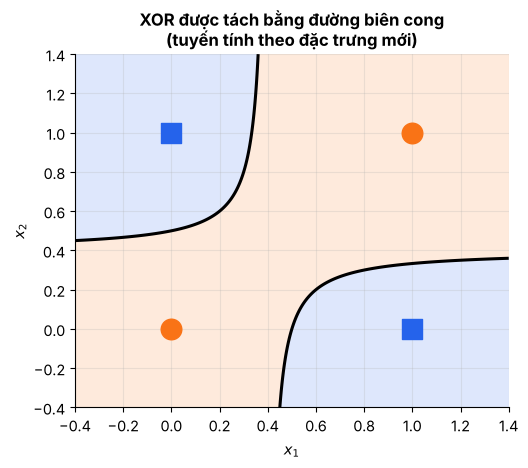

In [24]:
Xb_xor2 = np.c_[Xb_xor, X_xor[:, 0] * X_xor[:, 1]]       # thêm cột x1*x2: (4,3) -> (4,4)
w2, ls2, _ = huan_luyen(Xb_xor2, y_xor, t_max=50)
print("Số cập nhật mỗi epoch:", ls2, "-> hội tụ")
print("w' =", w2, " margin =", y_xor * (Xb_xor2 @ w2), " (mọi margin dương)")

u, v = np.meshgrid(np.linspace(-0.4, 1.4, 300), np.linspace(-0.4, 1.4, 300))
s_luoi = w2[0] + w2[1] * u + w2[2] * v + w2[3] * u * v   # điểm số trong không gian gốc
fig, ax = plt.subplots(figsize=(5.4, 4.8))
ax.contourf(u, v, np.where(s_luoi >= 0, 1, -1), levels=[-2, 0, 2], colors=[MAU_ROT, MAU_DAU], alpha=0.15)
ax.contour(u, v, s_luoi, levels=[0], colors="k", linewidths=2.2)
ve_du_lieu(ax, X_xor, y_xor, co=220)
ax.set_title("XOR được tách bằng đường biên cong\n(tuyến tính theo đặc trưng mới)")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
hien(fig, "h15_xor_dac_trung_moi")

---
# Mục 5. Cài đặt và đánh giá mô hình Perceptron

Các hàm `them_bias`, `du_doan`, `huan_luyen` ở ô 0 chính là cài đặt từ đầu (khoảng 20 dòng NumPy). Bảng đối chiếu ký hiệu toán với mã:

| Ký hiệu toán | Trong mã |
|---|---|
| $\mathbf{X}$ (cột đầu bằng 1) | `Xb = them_bias(X)` |
| $s_i=\mathbf{x}_i\mathbf{w}$ / $\mathbf{s}=\mathbf{X}\mathbf{w}$ | `Xb[i] @ w` / `Xb @ w` |
| $\hat{\mathbf{y}}=\mathrm{sign}(\mathbf{s})$ | `np.where(s >= 0, 1, -1)` |
| $m_i=y_is_i$ | `y[i] * (Xb[i] @ w)` |
| $\mathbf{w}\leftarrow\mathbf{w}+\eta y_i\mathbf{x}_i^T$ | `w = w + eta * y[i] * Xb[i]` |

## 5.2. Dữ liệu lớn hơn, tập huấn luyện và tập kiểm tra
Mô phỏng 400 sinh viên (mỗi lớp 200), hai nhóm **chồng lấn** như dữ liệu thật. Rồi **chia 70% huấn luyện / 30% kiểm tra**: tập kiểm tra được *giấu đi* khi học và chỉ dùng **một lần ở cuối** để đánh giá (giống học sinh ôn đề này nhưng thi đề mới).

Huấn luyện: 280 mẫu (149 đậu) | Kiểm tra: 120 mẫu (51 đậu)


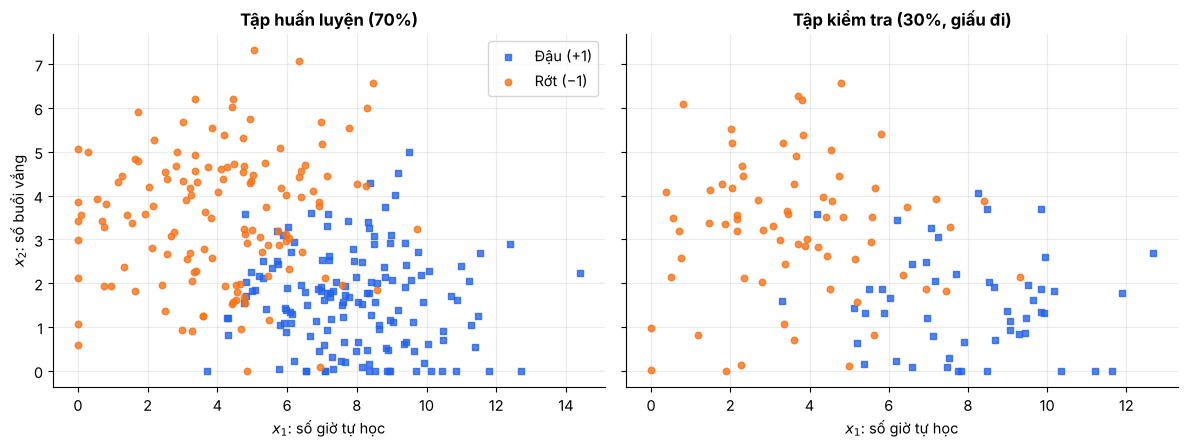

In [25]:
rng = np.random.default_rng(42)
n_lop = 200
dau = np.c_[rng.normal(8, 2.2, n_lop), rng.normal(1.5, 1.2, n_lop)]   # lớp +1: học nhiều, vắng ít
rot = np.c_[rng.normal(4, 2.2, n_lop), rng.normal(3.5, 1.5, n_lop)]   # lớp -1: học ít, vắng nhiều
X = np.clip(np.vstack([dau, rot]), 0, None)                           # giờ học, buổi vắng không âm
y = np.r_[np.ones(n_lop), -np.ones(n_lop)].astype(int)


def chia_train_test(X, y, ti_le_test=0.3, seed=0):
    """Xáo trộn rồi chia dữ liệu thành tập huấn luyện và tập kiểm tra."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))                  # một hoán vị ngẫu nhiên của 0..n-1
    n_test = int(len(y) * ti_le_test)
    # idx[:n_test] là chỉ số tập kiểm tra, phần còn lại là tập huấn luyện
    return X[idx[n_test:]], X[idx[:n_test]], y[idx[n_test:]], y[idx[:n_test]]


X_tr, X_te, y_tr, y_te = chia_train_test(X, y)
Xb_tr, Xb_te = them_bias(X_tr), them_bias(X_te)
print(f"Huấn luyện: {len(y_tr)} mẫu ({(y_tr == 1).sum()} đậu) | Kiểm tra: {len(y_te)} mẫu ({(y_te == 1).sum()} đậu)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (Xp, yp, ten) in zip(axes, [(X_tr, y_tr, "Tập huấn luyện (70%)"), (X_te, y_te, "Tập kiểm tra (30%, giấu đi)")]):
    ve_du_lieu(ax, Xp, yp, co=22, alpha=0.8)
    ax.set_title(ten)
    ax.set_xlabel("$x_1$: số giờ tự học")
axes[0].set_ylabel("$x_2$: số buổi vắng")
axes[0].legend()
hien(fig, "h16_chia_du_lieu")

**Quy tắc vàng:** tập kiểm tra **không** được dùng để chọn tham số, chọn $T_{\max}$ hay bất kỳ quyết định nào lúc huấn luyện, nếu không ước lượng sẽ quá lạc quan.

### Perceptron thuần túy không hội tụ trên dữ liệu chồng lấn

In [26]:
w_1, lich_su_1, _ = huan_luyen(Xb_tr, y_tr, t_max=100)
print(f"Số epoch đã chạy: {len(lich_su_1)} (đủ T_max = 100)  |  5 epoch cuối cập nhật: {lich_su_1[-5:]}")

Số epoch đã chạy: 100 (đủ T_max = 100)  |  5 epoch cuối cập nhật: [42, 45, 44, 42, 49]


Mỗi epoch vẫn còn hàng chục lần cập nhật: điều kiện dừng "không còn cập nhật" không bao giờ xảy ra (đúng như bài toán XOR, chỉ khác là ở đây dữ liệu chồng lấn).

### Thuật toán túi (pocket)
Giữ lại trong "túi" bộ $\mathbf{w}$ có **ít mẫu sai nhất trên tập huấn luyện** từ đầu đến giờ, và xáo trộn thứ tự mẫu ở mỗi epoch.

w_cuối = [-56.     12.73  -21.572] | w_túi = [-52.     18.135 -19.169]
Lỗi trên train: w_cuối = 69 | w_túi = 23 / 280


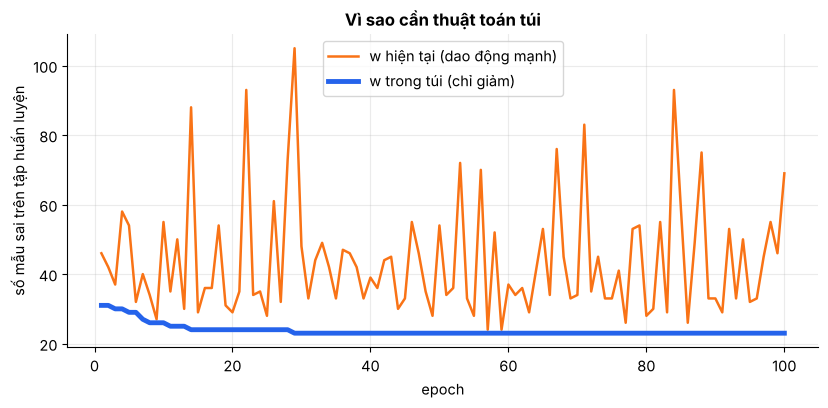

In [27]:
def huan_luyen_tui(Xb, y, eta=1.0, t_max=100, seed=0):
    """Perceptron + thuật toán túi. Trả về w cuối, w trong túi, lịch sử số mẫu sai."""
    n = Xb.shape[0]
    rng = np.random.default_rng(seed)
    w = np.zeros(Xb.shape[1])
    w_tui = w.copy()
    loi_tui = np.sum(du_doan(Xb, w) != y)
    lich_su = []                                  # mỗi phần tử: (số sai của w hiện tại, số sai của túi)
    for epoch in range(t_max):
        for i in rng.permutation(n):              # xáo trộn thứ tự mẫu mỗi epoch
            if y[i] * (Xb[i] @ w) <= 0:
                w = w + eta * y[i] * Xb[i]
                loi = np.sum(du_doan(Xb, w) != y) # đếm mẫu sai của w mới
                if loi < loi_tui:                 # tốt hơn mọi lần trước: cất vào túi
                    w_tui, loi_tui = w.copy(), loi
        lich_su.append((np.sum(du_doan(Xb, w) != y), loi_tui))
    return w, w_tui, np.array(lich_su)


w_last, w_tui, ls_tui = huan_luyen_tui(Xb_tr, y_tr)
print("w_cuối =", np.round(w_last, 3), "| w_túi =", np.round(w_tui, 3))
print(f"Lỗi trên train: w_cuối = {ls_tui[-1, 0]} | w_túi = {ls_tui[-1, 1]} / {len(y_tr)}")

fig, ax = plt.subplots(figsize=(8.4, 4.2))
ax.plot(np.arange(1, len(ls_tui) + 1), ls_tui[:, 0], color=MAU_ROT, lw=1.8, label="w hiện tại (dao động mạnh)")
ax.plot(np.arange(1, len(ls_tui) + 1), ls_tui[:, 1], color=MAU_DAU, lw=3.5, label="w trong túi (chỉ giảm)")
ax.set_xlabel("epoch")
ax.set_ylabel("số mẫu sai trên tập huấn luyện")
ax.set_title("Vì sao cần thuật toán túi")
ax.legend()
hien(fig, "h17_thuat_toan_tui")

**Giải thích mã.**
- `rng.permutation(n)` trả về một hoán vị ngẫu nhiên của `0..n-1`: duyệt mẫu theo thứ tự ngẫu nhiên khác nhau ở mỗi epoch.
- `du_doan(Xb, w) != y` tạo mảng True/False (sai/đúng) cho từng mẫu; `np.sum` đếm số `True`, tức số mẫu sai.
- `w.copy()` rất quan trọng: nếu viết `w_tui = w` thì cả hai tên cùng trỏ vào **một** mảng, và khi `w` thay đổi, "túi" cũng đổi theo. `copy()` tạo bản sao độc lập.

### Đường biên tìm được

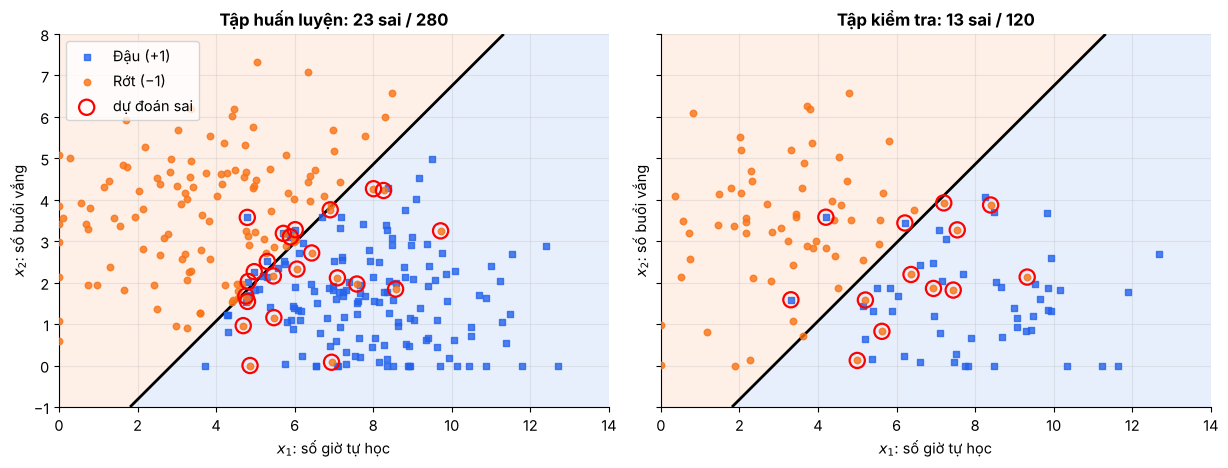

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8), sharey=True)
for ax, (Xp, yp, Xbp, ten) in zip(axes, [(X_tr, y_tr, Xb_tr, "Tập huấn luyện"), (X_te, y_te, Xb_te, "Tập kiểm tra")]):
    ve_du_lieu(ax, Xp, yp, co=22, alpha=0.8)
    ve_duong_bien(ax, w_tui, (0, 14), (-1, 8))
    sai = du_doan(Xbp, w_tui) != yp
    ax.scatter(*Xp[sai].T, s=120, facecolors="none", edgecolors="red", linewidths=1.6, zorder=4, label="dự đoán sai")
    ax.set_title(f"{ten}: {sai.sum()} sai / {len(yp)}")
axes[0].legend(loc="upper left")
hien(fig, "h18_duong_bien_tui")

Các mẫu bị khoanh đỏ tập trung ở **vùng hai lớp chồng lấn**: đó là giới hạn của dữ liệu, không phải lỗi của thuật toán.

## Đo bằng accuracy
$$\text{Accuracy}=\frac1n\sum_i \mathbb{1}[\hat y_i=y_i]$$
Trong mã chỉ là `np.mean(y == y_hat)`.

Bộ tham số                      train     test
w thuần túy (epoch 100)        0.8821   0.8583
w epoch cuối (có xáo trộn)     0.7536   0.8250
w túi                          0.9179   0.8917


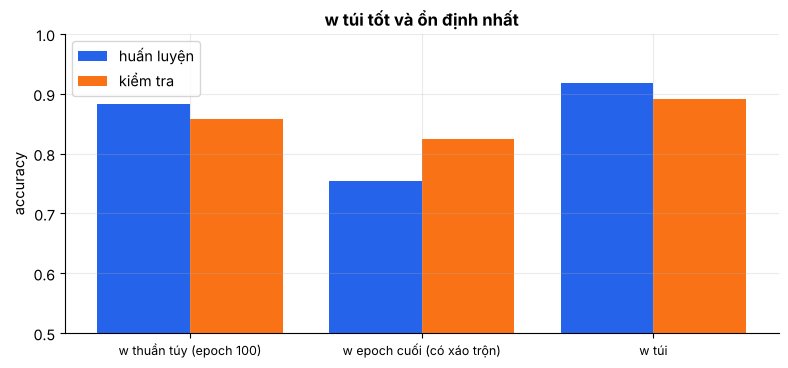

In [29]:
acc = lambda a, b: np.mean(a == b)           # trung bình của mảng True/False = tỉ lệ đúng
mo_hinh = {"w thuần túy (epoch 100)": w_1, "w epoch cuối (có xáo trộn)": w_last, "w túi": w_tui}
print(f"{'Bộ tham số':<28}{'train':>9}{'test':>9}")
for ten, w in mo_hinh.items():
    print(f"{ten:<28}{acc(y_tr, du_doan(Xb_tr, w)):>9.4f}{acc(y_te, du_doan(Xb_te, w)):>9.4f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
vi_tri = np.arange(len(mo_hinh))
ax.bar(vi_tri - 0.2, [acc(y_tr, du_doan(Xb_tr, w)) for w in mo_hinh.values()], 0.4, color=MAU_DAU, label="huấn luyện")
ax.bar(vi_tri + 0.2, [acc(y_te, du_doan(Xb_te, w)) for w in mo_hinh.values()], 0.4, color=MAU_ROT, label="kiểm tra")
ax.set_xticks(vi_tri)
ax.set_xticklabels(list(mo_hinh), fontsize=9)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("accuracy")
ax.set_title("w túi tốt và ổn định nhất")
ax.legend()
hien(fig, "h19_accuracy")

## Ma trận nhầm lẫn, precision, recall và F1
Accuracy chỉ cho biết **bao nhiêu** mẫu sai, không cho biết sai **kiểu nào**. Quy ước **lớp dương = "đậu"**:

| | Dự đoán đậu | Dự đoán rớt |
|---|---|---|
| **Thực tế đậu** | TP (đoán đậu, đúng) | **FN** (bỏ sót) |
| **Thực tế rớt** | **FP** (báo nhầm) | TN (đoán rớt, đúng) |

$$\text{Precision}=\frac{TP}{TP+FP},\qquad \text{Recall}=\frac{TP}{TP+FN},\qquad F1=\frac{2\,TP}{2\,TP+FP+FN}$$
- **Precision**: trong số sinh viên được dự đoán đậu, bao nhiêu % thật sự đậu? (thấp ⇒ hay *báo nhầm*)
- **Recall**: trong số sinh viên thật sự đậu, mô hình phát hiện được bao nhiêu %? (thấp ⇒ hay *bỏ sót*)
- **F1**: trung bình điều hòa, chỉ cao khi cả hai cùng cao.

[[59 10]
 [ 3 48]]
Accuracy = 0.892 | Precision = 0.828 | Recall = 0.941 | F1 = 0.881


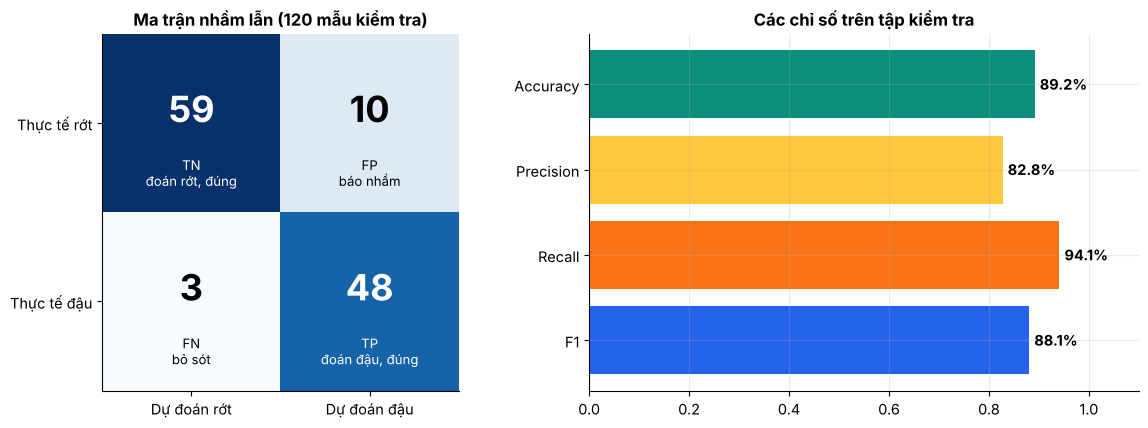

In [30]:
def ma_tran_nham_lan(y, y_hat):
    """C = [[TN, FP], [FN, TP]] (hàng: nhãn thực, cột: nhãn dự đoán), thứ tự lớp (-1, +1)."""
    tp = np.sum((y == 1) & (y_hat == 1))       # "&" là AND theo từng phần tử (cần ngoặc quanh mỗi điều kiện)
    tn = np.sum((y == -1) & (y_hat == -1))
    fp = np.sum((y == -1) & (y_hat == 1))
    fn = np.sum((y == 1) & (y_hat == -1))
    return np.array([[tn, fp], [fn, tp]])


y_hat_te = du_doan(Xb_te, w_tui)
C = ma_tran_nham_lan(y_te, y_hat_te)
(tn, fp), (fn, tp) = C                            # "mở" ma trận 2x2 thành 4 biến
precision, recall = tp / (tp + fp), tp / (tp + fn)
f1 = 2 * tp / (2 * tp + fp + fn)
print(C)
print(f"Accuracy = {(tp + tn) / C.sum():.3f} | Precision = {precision:.3f} | Recall = {recall:.3f} | F1 = {f1:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ax.imshow(C, cmap="Blues")
ten_o = [["TN\nđoán rớt, đúng", "FP\nbáo nhầm"], ["FN\nbỏ sót", "TP\nđoán đậu, đúng"]]
for a in range(2):
    for b in range(2):
        mau_chu = "white" if C[a, b] > C.max() / 2 else "black"
        ax.text(b, a - 0.08, str(C[a, b]), ha="center", va="center", fontsize=26, fontweight="bold", color=mau_chu)
        ax.text(b, a + 0.28, ten_o[a][b], ha="center", va="center", fontsize=9.5, color=mau_chu)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Dự đoán rớt", "Dự đoán đậu"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Thực tế rớt", "Thực tế đậu"])
ax.grid(False)
ax.set_title("Ma trận nhầm lẫn (120 mẫu kiểm tra)")

ax = axes[1]
ten_chi_so = ["Accuracy", "Precision", "Recall", "F1"]
gia_tri = [(tp + tn) / C.sum(), precision, recall, f1]
thanh = ax.barh(ten_chi_so[::-1], gia_tri[::-1], color=[MAU_NHAN, "#FFC83D", MAU_ROT, MAU_DAU][::-1])
for t, v in zip(thanh, gia_tri[::-1]):
    ax.text(v + 0.01, t.get_y() + t.get_height() / 2, f"{v:.1%}", va="center", fontweight="bold")
ax.set_xlim(0, 1.1)
ax.set_title("Các chỉ số trên tập kiểm tra")
hien(fig, "h20_ma_tran_nham_lan")

**Giải thích mã.** `(y == 1) & (y_hat == 1)` là **AND từng phần tử** giữa hai mảng True/False (dùng `&`, không dùng `and`, và phải đặt ngoặc quanh từng điều kiện). `np.sum` đếm số vị trí thoả cả hai điều kiện. Dòng `(tn, fp), (fn, tp) = C` gán lần lượt bốn phần tử của ma trận 2×2 cho bốn biến.

**Đọc kết quả:** mô hình phát hiện được ≈ 94% sinh viên đậu (recall cao) nhưng chỉ ≈ 83% số dự đoán "đậu" là đúng (precision thấp hơn): nó mắc lỗi **báo nhầm** nhiều hơn **bỏ sót**.

### Đổi ngưỡng để thấy sự đánh đổi precision ↔ recall
Perceptron gốc dùng ngưỡng 0 ($\hat y=+1$ khi $s\ge 0$). Ta có thể **dịch ngưỡng**: dự đoán "đậu" khi khoảng cách có dấu tới đường biên $\ge t$. Hạ ngưỡng ⇒ dễ nói "đậu" ⇒ recall tăng, precision giảm; nâng ngưỡng thì ngược lại. Tuỳ bài toán (tầm soát bệnh cần recall cao, lọc thư rác cần precision cao) ta chọn ngưỡng khác nhau.

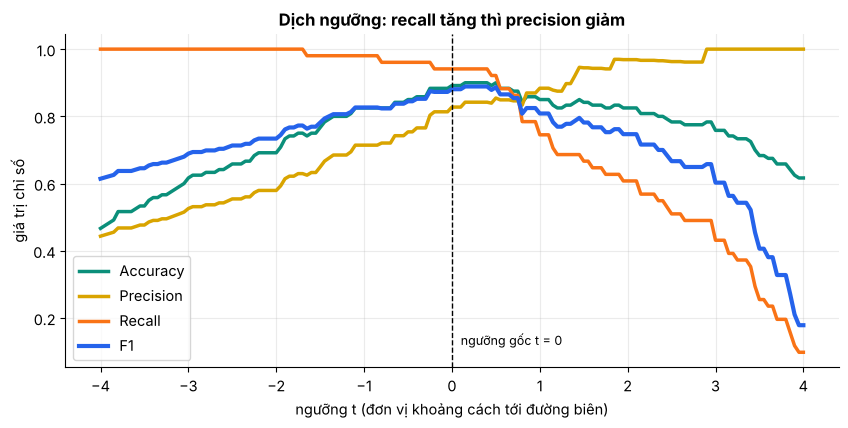

In [31]:
khoang_cach_co_dau = (Xb_te @ w_tui) / np.linalg.norm(w_tui[1:])      # s / ||w~||
cac_t = np.linspace(-4, 4, 161)
P, Rc, F, A = [], [], [], []
for t in cac_t:
    yh = np.where(khoang_cach_co_dau >= t, 1, -1)
    tn_, fp_, fn_, tp_ = ma_tran_nham_lan(y_te, yh).ravel()           # ravel(): ma trận 2x2 -> dãy 4 số
    P.append(tp_ / (tp_ + fp_) if tp_ + fp_ else np.nan)              # tránh chia cho 0
    Rc.append(tp_ / (tp_ + fn_))
    F.append(2 * tp_ / (2 * tp_ + fp_ + fn_))
    A.append((tp_ + tn_) / len(y_te))

fig, ax = plt.subplots(figsize=(8.6, 4.4))
ax.plot(cac_t, A, color=MAU_NHAN, lw=2.5, label="Accuracy")
ax.plot(cac_t, P, color="#D9A400", lw=2.5, label="Precision")
ax.plot(cac_t, Rc, color=MAU_ROT, lw=2.5, label="Recall")
ax.plot(cac_t, F, color=MAU_DAU, lw=3, label="F1")
ax.axvline(0, color="k", ls="--", lw=1)
ax.text(0.1, 0.12, "ngưỡng gốc t = 0", fontsize=9)
ax.set_xlabel("ngưỡng t (đơn vị khoảng cách tới đường biên)")
ax.set_ylabel("giá trị chỉ số")
ax.set_title("Dịch ngưỡng: recall tăng thì precision giảm")
ax.legend()
hien(fig, "h21_dich_nguong")

### Cạm bẫy của accuracy khi dữ liệu lệch lớp
Giả sử 100 mẫu có 95 âm, 5 dương, và một mô hình "lười" luôn dự đoán −1. Accuracy = 95%, nhưng recall = 0: không phát hiện được mẫu dương nào.

In [32]:
y_lech = np.r_[-np.ones(95), np.ones(5)].astype(int)
y_luoi = -np.ones(100, dtype=int)                    # luôn đoán -1
tn_, fp_, fn_, tp_ = ma_tran_nham_lan(y_lech, y_luoi).ravel()
print(f"Accuracy = {(tp_ + tn_) / 100:.0%}  nhưng  Recall = {tp_ / (tp_ + fn_):.0%}")
print("-> Với dữ liệu lệch lớp, luôn xem ma trận nhầm lẫn, precision và recall, đừng chỉ nhìn accuracy.")

Accuracy = 95%  nhưng  Recall = 0%
-> Với dữ liệu lệch lớp, luôn xem ma trận nhầm lẫn, precision và recall, đừng chỉ nhìn accuracy.


## 5.3. So sánh với scikit-learn
Lớp `Perceptron` của scikit-learn thực chất chạy cùng thuật toán. Để so sánh công bằng ta tắt xáo trộn (`shuffle=False`) và dừng sớm (`tol=None`).

In [33]:
try:
    from sklearn.linear_model import Perceptron, LinearRegression
    from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
    co_sklearn = True
except ImportError:
    co_sklearn = False
    print("Chưa cài scikit-learn: chạy `pip install scikit-learn` để chạy phần này.")

if co_sklearn:
    clf = Perceptron(eta0=1.0, max_iter=20, tol=None, shuffle=False).fit(X_sv, y_sv)   # lưu ý: truyền X KHÔNG có cột 1
    print("6 sinh viên  | sklearn: intercept_ =", clf.intercept_, " coef_ =", clf.coef_)
    print("             | tự cài đặt: w =", huan_luyen(Xb_sv, y_sv)[0])

    clf = Perceptron(eta0=1.0, max_iter=100, tol=None, shuffle=False).fit(X_tr, y_tr)
    print("Dữ liệu lớn  | sklearn: intercept_ =", clf.intercept_, " coef_ =", np.round(clf.coef_, 3))
    print("             | tự cài đặt: w =", np.round(w_1, 3), "(trùng nhau)")

6 sinh viên  | sklearn: intercept_ = [-1.]  coef_ = [[ 4. -8.]]
             | tự cài đặt: w = [-1.  4. -8.]
Dữ liệu lớn  | sklearn: intercept_ = [-65.]  coef_ = [[ 27.118 -27.472]]
             | tự cài đặt: w = [-65.     27.118 -27.472] (trùng nhau)


**Giải thích.** scikit-learn **tự quản lý hệ số chệch**: ta truyền thẳng `X` (không có cột 1), $w_0$ nằm riêng trong `intercept_`, còn $w_1,\dots,w_d$ nằm trong `coef_`. Ghép lại ta được đúng $\mathbf{w}$ của mã tự cài đặt. Ngoài ra khác biệt khi dùng cấu hình mặc định: thư viện **xáo trộn mẫu** (`shuffle=True`), **dừng sớm** theo `tol`, và với mẫu có $s=0$ thì dự đoán lớp thứ nhất (−1) thay vì +1.

### So sánh ba mô hình và dùng hàm đánh giá có sẵn

In [34]:
if co_sklearn:
    clf_mac_dinh = Perceptron(random_state=0).fit(X_tr, y_tr)
    hq = LinearRegression().fit(X_tr, y_tr)                              # hồi quy rồi đặt ngưỡng 0
    du_doan_hq = lambda X_: np.where(hq.predict(X_) >= 0, 1, -1)
    hang = [("Perceptron tự cài đặt (w túi)", du_doan(Xb_tr, w_tui), du_doan(Xb_te, w_tui)),
            ("sklearn Perceptron (mặc định)", clf_mac_dinh.predict(X_tr), clf_mac_dinh.predict(X_te)),
            ("Hồi quy tuyến tính + ngưỡng 0", du_doan_hq(X_tr), du_doan_hq(X_te))]
    print(f"{'Mô hình':<34}{'train':>8}{'test':>8}")
    for ten, a, b in hang:
        print(f"{ten:<34}{accuracy_score(y_tr, a):>8.4f}{accuracy_score(y_te, b):>8.4f}")

    print("\nMa trận nhầm lẫn bằng sklearn (phải khớp với bảng tính tay):")
    print(confusion_matrix(y_te, y_hat_te, labels=[-1, 1]))
    print(classification_report(y_te, y_hat_te, labels=[-1, 1], target_names=["rot", "dau"], digits=3))

Mô hình                              train    test
Perceptron tự cài đặt (w túi)       0.9179  0.8917
sklearn Perceptron (mặc định)       0.9071  0.8917
Hồi quy tuyến tính + ngưỡng 0       0.9071  0.8917

Ma trận nhầm lẫn bằng sklearn (phải khớp với bảng tính tay):
[[59 10]
 [ 3 48]]
              precision    recall  f1-score   support

         rot      0.952     0.855     0.901        69
         dau      0.828     0.941     0.881        51

    accuracy                          0.892       120
   macro avg      0.890     0.898     0.891       120
weighted avg      0.899     0.892     0.892       120



Ba mô hình cho kết quả **gần như bằng nhau** ở đây vì dữ liệu cân bằng và không có ngoại lai cực đoan. Điểm yếu của hồi quy-rồi-đặt-ngưỡng (mục 1.2) hiện ra khi có mẫu "rất đúng" hoặc ngoại lai.

---
# Tóm tắt
1. **Phân loại ≠ hồi quy**: MSE đo khoảng cách tới ±1 chứ không đo đúng/sai; cần mô hình ra nhãn và mất mát phản ánh đúng/sai.
2. **Perceptron**: $\hat y=\mathrm{sign}(\mathbf{x}\mathbf{w})$, đường biên $\mathbf{x}\mathbf{w}=0$; $\tilde{\mathbf{w}}$ là pháp tuyến, $w_0$ dịch biên; margin $m=y\,s>0$ nghĩa là đúng.
3. **Huấn luyện**: mất mát $\max(0,-m)$; mẫu sai ($m\le0$) thì $\mathbf{w}\leftarrow\mathbf{w}+\eta y\mathbf{x}^T$; lặp theo epoch tới khi một epoch không còn cập nhật.
4. **Cơ chế học**: nghiệm không duy nhất (phụ thuộc thứ tự, khởi tạo); tách được ⇔ dừng sau tối đa $R^2/\gamma^2$ lần; XOR không tách được nên quay vòng, cần $T_{\max}$, thuật toán túi hoặc đặc trưng mới.
5. **Đánh giá**: chia train/test; accuracy, ma trận nhầm lẫn, precision, recall, F1; với dữ liệu lệch lớp đừng chỉ nhìn accuracy.

Ảnh của mọi hình được lưu trong thư mục `hinh_perceptron/`.